# FracAtlas Fracture Segmentation Research

This notebook implements the complete first research phase: VGG polygon auditing, binary-mask generation, full-radiograph preprocessing, reproducible image-level splitting, and a checkpoint-first Vanilla U-Net baseline. The task is binary segmentation with background `0` and fracture region `1`. Images remain complete radiographs and are resized to `(width=512, height=640)` without cropping or stretching.

Only images referenced by the VGG JSON are used. Training uses AdamW, a `0.5 BCE + 0.5 Dice` objective, effective batch size 4 through gradient accumulation, and FP16 AMP when CUDA supports it. Later architectures should use their own prefixed functions and checkpoint directories.

## 1. Project configuration
All paths and experiment values are centralized here. The dataset is intentionally not searched for elsewhere. Change `DATASET_ROOT` if the expected directory is not present.

In [7]:
from pathlib import Path
import os, json, random, sys, time, platform, hashlib, shutil
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

DATASET_ROOT = Path('dataset_dir/FracAtlas')
FRACTURED_DIR = DATASET_ROOT / 'images' / 'Fractured'
NON_FRACTURED_DIR = DATASET_ROOT / 'images' / 'Non_fractured'
ANNOTATION_DIR = DATASET_ROOT / 'Annotations' / 'VGG JSON'
ANNOTATION_JSON = ANNOTATION_DIR / 'VGG_fracture_masks.json'
OUTPUT_ROOT = Path('outputs')
PREPROCESSING_ROOT = OUTPUT_ROOT / 'preprocessing'
MASK_DIR = PREPROCESSING_ROOT / 'masks'
SPLIT_DIR = PREPROCESSING_ROOT / 'splits'
AUDIT_DIR = OUTPUT_ROOT / 'audit'
CHECKPOINT_DIR = OUTPUT_ROOT / 'checkpoints' / 'vanilla_unet'
HISTORY_DIR = OUTPUT_ROOT / 'histories' / 'vanilla_unet'
EVAL_DIR = OUTPUT_ROOT / 'evaluation' / 'vanilla_unet'
VIZ_DIR = OUTPUT_ROOT / 'visualizations' / 'vanilla_unet'
BASELINE_CONFIG_DIR = OUTPUT_ROOT / 'experiment_configs'
BASELINE_CONFIG_PATH = BASELINE_CONFIG_DIR / 'vanilla_unet.json'
BASELINE_STATUS_PATH = OUTPUT_ROOT / 'experiment_status' / 'vanilla_unet.json'

BASELINE_SEED = 42
BASELINE_IMAGE_WIDTH, BASELINE_IMAGE_HEIGHT = 512, 640
BASELINE_TRAIN_RATIO, BASELINE_VAL_RATIO, BASELINE_TEST_RATIO = 0.70, 0.15, 0.15
BASELINE_PHYSICAL_BATCH_SIZE = 2
BASELINE_FALLBACK_BATCH_SIZE = 1
BASELINE_GRAD_ACCUMULATION_STEPS = 2
BASELINE_FALLBACK_ACCUMULATION_STEPS = 4
BASELINE_EPOCHS = 20
BASELINE_LEARNING_RATE = 1e-3
BASELINE_WEIGHT_DECAY = 1e-4
BASELINE_BCE_WEIGHT, BASELINE_DICE_WEIGHT = 0.5, 0.5
BASELINE_THRESHOLD = 0.5
BASELINE_NUM_WORKERS = 0
BASELINE_ROTATION_DEGREES = 5.0

for path in [MASK_DIR, SPLIT_DIR, AUDIT_DIR, CHECKPOINT_DIR, HISTORY_DIR, EVAL_DIR, BASELINE_CONFIG_DIR, BASELINE_STATUS_PATH.parent, VIZ_DIR / 'dataset_samples', VIZ_DIR / 'annotation_overlays', VIZ_DIR / 'training_curves', VIZ_DIR / 'test_predictions']:
    path.mkdir(parents=True, exist_ok=True)
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f'Dataset root not found: {DATASET_ROOT.resolve()}. Change DATASET_ROOT to the configured FracAtlas directory.')
required_paths = [FRACTURED_DIR, NON_FRACTURED_DIR, ANNOTATION_DIR, ANNOTATION_JSON]
missing_paths = [str(p) for p in required_paths if not p.exists()]
if missing_paths:
    raise FileNotFoundError('Missing required FracAtlas paths:\n' + '\n'.join(missing_paths))

BASELINE_CONFIG = {
    'experiment_name': 'vanilla_unet', 'dataset_root': str(DATASET_ROOT), 'annotation_json': str(ANNOTATION_JSON),
    'shared_preprocessing_root': str(PREPROCESSING_ROOT), 'shared_mask_dir': str(MASK_DIR), 'shared_split_dir': str(SPLIT_DIR),
    'seed': BASELINE_SEED, 'image_width': BASELINE_IMAGE_WIDTH, 'image_height': BASELINE_IMAGE_HEIGHT,
    'split_ratios': [BASELINE_TRAIN_RATIO, BASELINE_VAL_RATIO, BASELINE_TEST_RATIO],
    'physical_batch_size': BASELINE_PHYSICAL_BATCH_SIZE, 'gradient_accumulation_steps': BASELINE_GRAD_ACCUMULATION_STEPS,
    'epochs': BASELINE_EPOCHS, 'learning_rate': BASELINE_LEARNING_RATE, 'weight_decay': BASELINE_WEIGHT_DECAY,
    'loss_weights': [BASELINE_BCE_WEIGHT, BASELINE_DICE_WEIGHT], 'threshold': BASELINE_THRESHOLD,
    'num_workers': BASELINE_NUM_WORKERS, 'architecture': 'Vanilla U-Net', 'channels': [16, 32, 64, 128, 256],
    'checkpoint_dir': str(CHECKPOINT_DIR), 'history_dir': str(HISTORY_DIR), 'evaluation_dir': str(EVAL_DIR), 'visualization_dir': str(VIZ_DIR)
}
BASELINE_CONFIG_PATH.write_text(json.dumps(BASELINE_CONFIG, indent=2))
random.seed(BASELINE_SEED); np.random.seed(BASELINE_SEED)
print(json.dumps(BASELINE_CONFIG, indent=2))

{
  "experiment_name": "vanilla_unet",
  "dataset_root": "dataset_dir/FracAtlas",
  "annotation_json": "dataset_dir/FracAtlas/Annotations/VGG JSON/VGG_fracture_masks.json",
  "shared_preprocessing_root": "outputs/preprocessing",
  "shared_mask_dir": "outputs/preprocessing/masks",
  "shared_split_dir": "outputs/preprocessing/splits",
  "seed": 42,
  "image_width": 512,
  "image_height": 640,
  "split_ratios": [
    0.7,
    0.15,
    0.15
  ],
  "physical_batch_size": 2,
  "gradient_accumulation_steps": 2,
  "epochs": 20,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "loss_weights": [
    0.5,
    0.5
  ],
  "threshold": 0.5,
  "num_workers": 0,
  "architecture": "Vanilla U-Net",
  "channels": [
    16,
    32,
    64,
    128,
    256
  ],
  "checkpoint_dir": "outputs/checkpoints/vanilla_unet",
  "history_dir": "outputs/histories/vanilla_unet",
  "evaluation_dir": "outputs/evaluation/vanilla_unet",
  "visualization_dir": "outputs/visualizations/vanilla_unet"
}


## 2. Environment and GPU verification
The notebook uses installed packages from the active virtual environment and never installs dependencies.

In [8]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from sklearn.model_selection import train_test_split

print({'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__, 'numpy': np.__version__, 'opencv': cv2.__version__, 'pillow': Image.__version__, 'pandas': pd.__version__})
print({'cuda_available': torch.cuda.is_available(), 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, 'gpu_memory_gb': round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2) if torch.cuda.is_available() else None, 'amp_available': hasattr(torch.cuda, 'amp') and torch.cuda.is_available()})
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BASELINE_AMP_ENABLED = DEVICE.type == 'cuda'

{'python': '3.14.7', 'platform': 'Linux-7.2.8-arch1-2-x86_64-with-glibc2.44', 'torch': '2.15.0+cu132', 'numpy': '2.5.4', 'opencv': '5.0.0', 'pillow': '13.0.0', 'pandas': '3.1.1'}
{'cuda_available': True, 'gpu': 'NVIDIA GeForce RTX 3050 Laptop GPU', 'gpu_memory_gb': 3.73, 'amp_available': True}


## 3. Dataset discovery and inspection
Discovery is limited to the configured FracAtlas directories. The counts distinguish all JPGs from the annotated subset.

In [9]:
def baseline_list_jpgs(directory):
    return sorted([p for p in directory.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg'}])

baseline_fractured_files = baseline_list_jpgs(FRACTURED_DIR)
baseline_nonfractured_files = baseline_list_jpgs(NON_FRACTURED_DIR)
baseline_annotation_files = [p for p in ANNOTATION_DIR.iterdir() if p.is_file()]
baseline_discovery = pd.DataFrame([
    ['Fractured JPGs', len(baseline_fractured_files)], ['Non-Fractured JPGs', len(baseline_nonfractured_files)],
    ['Total JPGs', len(baseline_fractured_files) + len(baseline_nonfractured_files)], ['Annotation-directory files', len(baseline_annotation_files)]
], columns=['item', 'count'])
display(baseline_discovery)
print('Fractured examples:', [p.name for p in baseline_fractured_files[:5]])
print('Non-Fractured examples:', [p.name for p in baseline_nonfractured_files[:5]])

def baseline_image_info(paths):
    rows = []
    for path in paths:
        image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if image is None:
            rows.append({'filename': path.name, 'error': 'unreadable'}); continue
        rows.append({'filename': path.name, 'width': image.shape[1], 'height': image.shape[0], 'channels': 1 if image.ndim == 2 else image.shape[2], 'dtype': str(image.dtype), 'min': int(image.min()), 'max': int(image.max()), 'grayscale': bool(image.ndim == 2 or image.shape[2] == 1)})
    return pd.DataFrame(rows)
baseline_inspection = baseline_image_info(baseline_fractured_files[:8])
display(baseline_inspection)
print('Dimension distribution among inspected images:')
display(baseline_inspection.groupby(['width', 'height']).size().rename('count').reset_index())

,item,count
0,Fractured JPGs,717
1,Non-Fractured JPGs,3366
2,Total JPGs,4083
3,Annotation-directory files,1


Fractured examples: ['IMG0000019.jpg', 'IMG0000025.jpg', 'IMG0000044.jpg', 'IMG0000057.jpg', 'IMG0000058.jpg']
Non-Fractured examples: ['IMG0000000.jpg', 'IMG0000001.jpg', 'IMG0000002.jpg', 'IMG0000003.jpg', 'IMG0000004.jpg']


,filename,width,height,channels,dtype,min,max,grayscale
0,IMG0000019.jpg,2304,2880,1,uint8,0,255,True
1,IMG0000025.jpg,2880,2304,1,uint8,0,254,True
2,IMG0000044.jpg,2304,2880,1,uint8,0,255,True
3,IMG0000057.jpg,2304,2880,1,uint8,0,255,True
4,IMG0000058.jpg,2304,2880,1,uint8,0,255,True
5,IMG0000059.jpg,2304,2880,1,uint8,0,255,True
6,IMG0000092.jpg,2304,2880,1,uint8,0,255,True
7,IMG0000100.jpg,2304,2880,1,uint8,0,255,True


Dimension distribution among inspected images:


,width,height,count
0,2304,2880,7
1,2880,2304,1


## 4. VGG JSON loading and annotation audit
The loader supports the standard VIA `_via_img_metadata` mapping and list-like variants. Malformed regions are recorded explicitly; only valid polygons are rasterized. An image with no valid polygon is excluded rather than used as a negative example.

In [10]:
baseline_vgg_raw = json.loads(ANNOTATION_JSON.read_text())
baseline_entries = baseline_vgg_raw.get('_via_img_metadata', baseline_vgg_raw) if isinstance(baseline_vgg_raw, dict) else baseline_vgg_raw
if isinstance(baseline_entries, dict): baseline_entries = list(baseline_entries.values())

def baseline_audit_vgg_entries(entries):
    records, invalid, missing, polygon_counts, labels, vertices = [], [], [], [], [], []
    image_map = {p.name: p for p in baseline_fractured_files}
    for entry in entries:
        filename = str(entry.get('filename', '')).strip() if isinstance(entry, dict) else ''
        image_path = image_map.get(filename)
        if image_path is None: missing.append(filename)
        regions = entry.get('regions', []) if isinstance(entry, dict) else []
        if isinstance(regions, dict): regions = list(regions.values())
        valid_regions = []
        for region_index, region in enumerate(regions):
            shape = region.get('shape_attributes', {}) if isinstance(region, dict) else {}
            attrs = region.get('region_attributes', {}) if isinstance(region, dict) else {}
            xs, ys = shape.get('all_points_x'), shape.get('all_points_y')
            reason = None
            if shape.get('name') != 'polygon': reason = 'shape is not polygon'
            elif not isinstance(xs, list) or not isinstance(ys, list) or len(xs) != len(ys) or len(xs) < 3: reason = 'invalid coordinate arrays'
            else:
                try: points = np.asarray(list(zip(xs, ys)), dtype=np.float32)
                except Exception: reason = 'non-numeric coordinates'
                if reason is None and (not np.isfinite(points).all() or not np.isfinite(points).all(axis=1).all()): reason = 'non-finite coordinates'
                if reason is None and image_path is not None:
                    shape_image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
                    h, w = shape_image.shape[:2]
                    if (points[:, 0] < 0).any() or (points[:, 0] >= w).any() or (points[:, 1] < 0).any() or (points[:, 1] >= h).any(): reason = 'out-of-bounds coordinates'
            if reason:
                invalid.append({'filename': filename, 'region_index': region_index, 'reason': reason}); continue
            valid_regions.append({'xs': [int(round(x)) for x in xs], 'ys': [int(round(y)) for y in ys], 'label': attrs.get('label', '')})
            labels.append(str(attrs.get('label', ''))) ; vertices.append(len(xs))
        if valid_regions and image_path is not None:
            polygon_counts.append(len(valid_regions)); records.append({'image_id': Path(filename).stem, 'filename': filename, 'image_path': str(image_path), 'regions': valid_regions})
    audit = {'json_entries': len(entries), 'unique_annotated_filenames': len({r.get('filename', '') for r in entries if isinstance(r, dict)}), 'polygon_regions': int(sum(polygon_counts)), 'region_labels': pd.Series(labels).value_counts().to_dict(), 'vertex_count_distribution': pd.Series(vertices).value_counts().sort_index().to_dict(), 'images_with_one_polygon': int(sum(n == 1 for n in polygon_counts)), 'images_with_multiple_polygons': int(sum(n > 1 for n in polygon_counts)), 'missing_corresponding_jpgs': missing, 'malformed_annotations': invalid, 'valid_images': len(records)}
    return records, audit

baseline_annotation_records, baseline_annotation_audit = baseline_audit_vgg_entries(baseline_entries)
(AUDIT_DIR / 'annotation_validation.json').write_text(json.dumps(baseline_annotation_audit, indent=2))
display(pd.DataFrame([{'metric': k, 'value': v if not isinstance(v, (list, dict)) else json.dumps(v)} for k, v in baseline_annotation_audit.items()]))
if baseline_annotation_audit['malformed_annotations']:
    print('Malformed entries were excluded from masks; see audit/annotation_validation.json.')
if not baseline_annotation_records:
    raise RuntimeError('No valid annotated images remain after VGG validation.')

,metric,value
0,json_entries,717
1,unique_annotated_filenames,717
2,polygon_regions,912
3,region_labels,"{""fractured"": 912}"
4,vertex_count_distribution,"{""4"": 1, ""5"": 167, ""6"": 233, ""7"": 219, ""8"": 11..."
5,images_with_one_polygon,549
6,images_with_multiple_polygons,166
7,missing_corresponding_jpgs,[]
8,malformed_annotations,"[{""filename"": ""IMG0002342.jpg"", ""region_index""..."
9,valid_images,715


Malformed entries were excluded from masks; see audit/annotation_validation.json.


## 5. Polygon-to-binary-mask conversion
Masks are rasterized at each source image's original dimensions, then cached under `outputs/preprocessing/masks`. Existing masks are reused when their source metadata matches the current annotation record.

In [11]:
def baseline_record_signature(record):
    return hashlib.sha256(json.dumps(record, sort_keys=True).encode()).hexdigest()

baseline_mask_records = []
for record in baseline_annotation_records:
    image = cv2.imread(record['image_path'], cv2.IMREAD_GRAYSCALE)
    height, width = image.shape
    mask_path = MASK_DIR / f"{record['image_id']}.png"
    meta_path = MASK_DIR / f"{record['image_id']}.json"
    signature = baseline_record_signature(record)
    reusable = mask_path.exists() and meta_path.exists() and json.loads(meta_path.read_text()).get('signature') == signature
    if not reusable:
        mask = np.zeros((height, width), dtype=np.uint8)
        for polygon in record['regions']:
            points = np.asarray(list(zip(polygon['xs'], polygon['ys'])), dtype=np.int32)
            cv2.fillPoly(mask, [points], 1)
        if set(np.unique(mask)) - {0, 1}: raise ValueError(f'Non-binary generated mask: {mask_path}')
        cv2.imwrite(str(mask_path), mask)
        meta_path.write_text(json.dumps({'signature': signature, 'image_id': record['image_id'], 'shape': [height, width], 'polygon_count': len(record['regions'])}, indent=2))
    baseline_mask_records.append({'image_id': record['image_id'], 'filename': record['filename'], 'image_path': record['image_path'], 'mask_path': str(mask_path), 'polygon_count': len(record['regions'])})
baseline_mask_metadata = {'records': len(baseline_mask_records), 'mask_directory': str(MASK_DIR), 'source_annotation': str(ANNOTATION_JSON), 'invalid_entries_excluded': len(baseline_annotation_audit['malformed_annotations'])}
(AUDIT_DIR / 'dataset_audit.json').write_text(json.dumps({'fractured_jpgs': len(baseline_fractured_files), 'nonfractured_jpgs': len(baseline_nonfractured_files), 'annotated_records': baseline_mask_metadata['records'], **baseline_annotation_audit}, indent=2))
print(f"Prepared {len(baseline_mask_records)} cached binary masks.")

Prepared 715 cached binary masks.


## 6. Image and mask validation
This gate checks source/mask alignment, binary values, and representative one- and multi-polygon examples before splitting or training.

,image_id,width,height,polygon_count,mask_values,positive_pixels,fracture_percent
0,IMG0000019,2304,2880,1,"[0, 1]",25430,0.383240
1,IMG0000025,2880,2304,1,"[0, 1]",15434,0.232597
2,IMG0000044,2304,2880,1,"[0, 1]",13158,0.198296
3,IMG0000057,2304,2880,1,"[0, 1]",9846,0.148383
4,IMG0000058,2304,2880,1,"[0, 1]",10709,0.161389


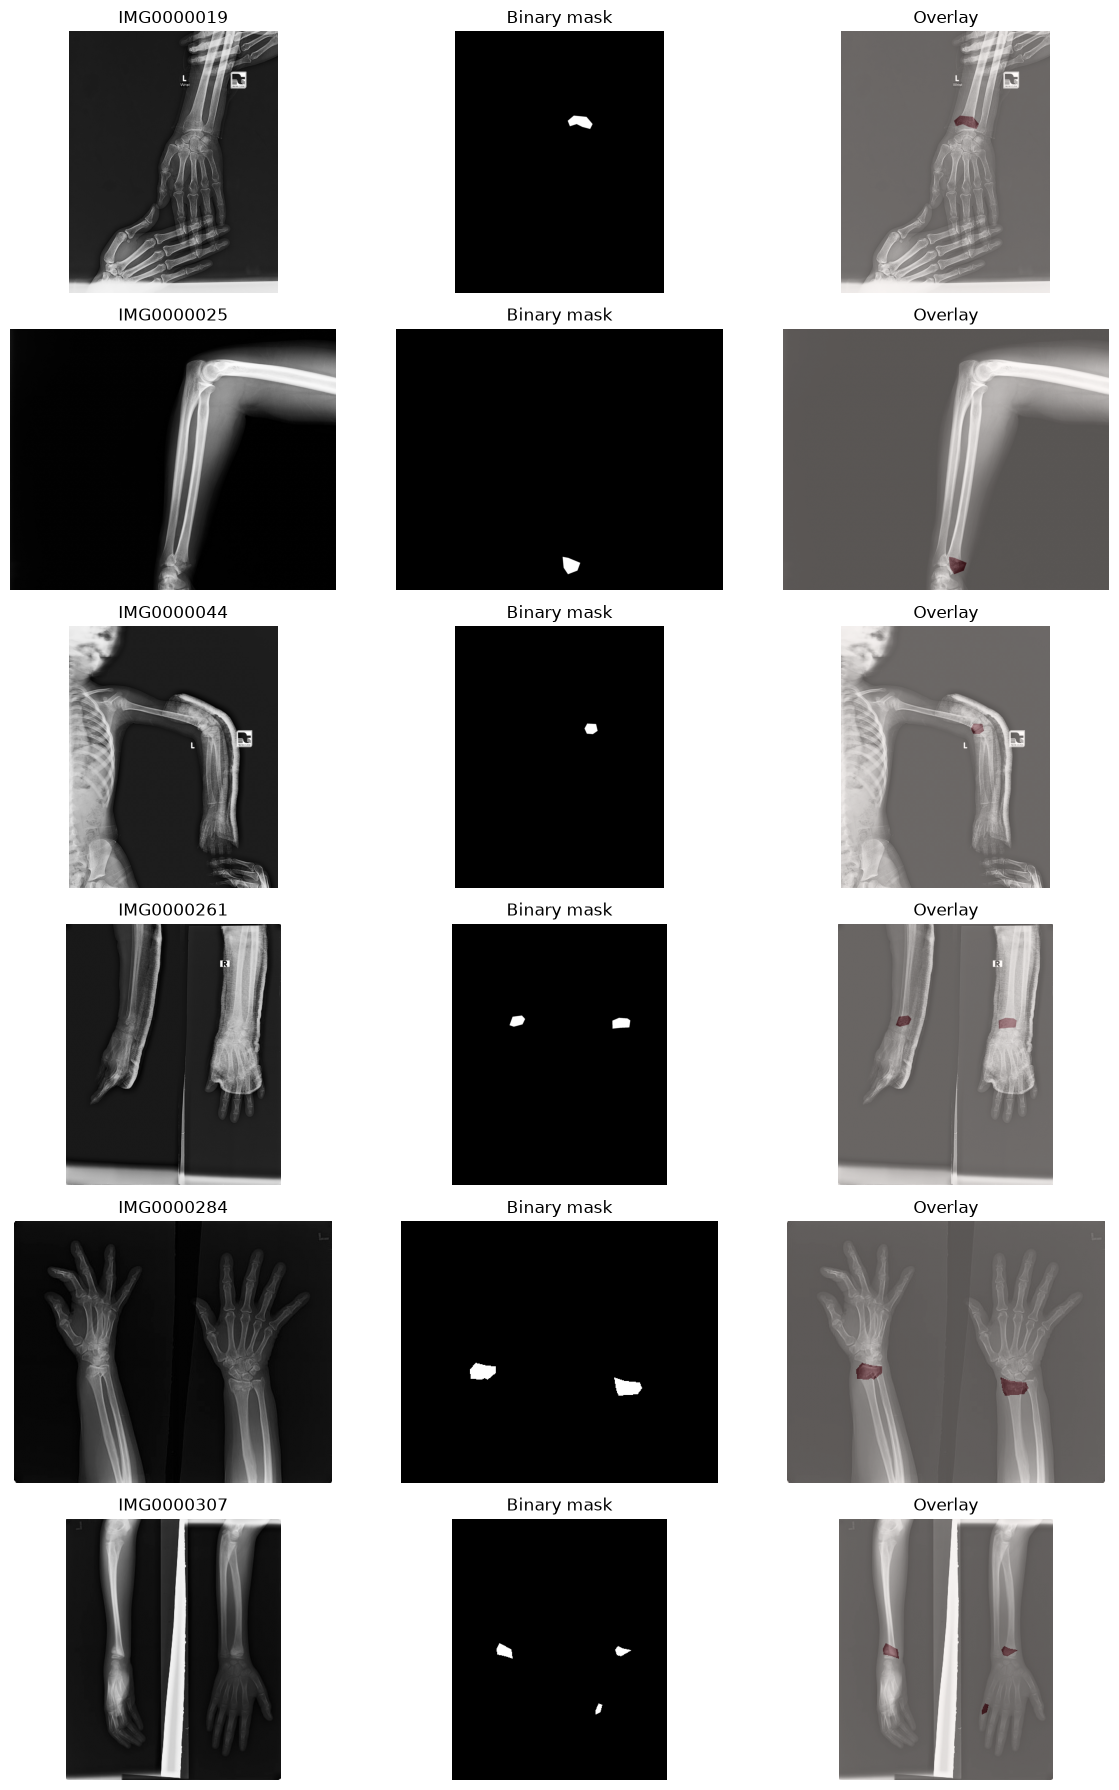

In [12]:
def baseline_validate_mask_records(records):
    rows = []
    for record in records:
        image = cv2.imread(record['image_path'], cv2.IMREAD_GRAYSCALE); mask = cv2.imread(record['mask_path'], cv2.IMREAD_UNCHANGED)
        if image is None or mask is None: raise RuntimeError(f'Unreadable image/mask: {record["image_id"]}')
        if image.shape != mask.shape: raise RuntimeError(f'Image-mask mismatch: {record["image_id"]} {image.shape} != {mask.shape}')
        values = set(np.unique(mask).tolist())
        if not values.issubset({0, 1}): raise RuntimeError(f'Non-binary mask values for {record["image_id"]}: {values}')
        positive = int(mask.sum()); total = int(mask.size)
        rows.append({**record, 'height': image.shape[0], 'width': image.shape[1], 'mask_values': sorted(values), 'positive_pixels': positive, 'background_pixels': total - positive, 'fracture_percent': 100 * positive / total})
    return pd.DataFrame(rows)
baseline_validation_df = baseline_validate_mask_records(baseline_mask_records)
display(baseline_validation_df[['image_id', 'width', 'height', 'polygon_count', 'mask_values', 'positive_pixels', 'fracture_percent']].head())

def baseline_show_annotation_examples(df, count=6):
    sample = pd.concat([df[df.polygon_count == 1].head(3), df[df.polygon_count > 1].head(3)]).drop_duplicates('image_id').head(count)
    fig, axes = plt.subplots(len(sample), 3, figsize=(12, max(3, 3 * len(sample))))
    axes = np.atleast_2d(axes)
    for row, (_, record) in enumerate(sample.iterrows()):
        image = cv2.imread(record.image_path, cv2.IMREAD_GRAYSCALE); mask = cv2.imread(record.mask_path, cv2.IMREAD_GRAYSCALE)
        axes[row, 0].imshow(image, cmap='gray'); axes[row, 1].imshow(mask, cmap='gray', vmin=0, vmax=1); axes[row, 2].imshow(image, cmap='gray'); axes[row, 2].imshow(mask, cmap='Reds', alpha=0.35, vmin=0, vmax=1)
        axes[row, 0].set_title(record.image_id); axes[row, 1].set_title('Binary mask'); axes[row, 2].set_title('Overlay')
        for axis in axes[row]: axis.axis('off')
    plt.tight_layout(); plt.show()
baseline_show_annotation_examples(baseline_validation_df)

## 7. Dataset exploratory analysis
The plots describe only annotated images and their generated masks.

{'annotated_images': 715, 'polygon_regions': 912, 'fracture_percent_min': np.float64(0.06376290027006173), 'fracture_percent_max': np.float64(2.9537858298591018), 'fracture_percent_median': np.float64(0.34486423923185033), 'fracture_percent_mean': np.float64(0.48961555661647427)}


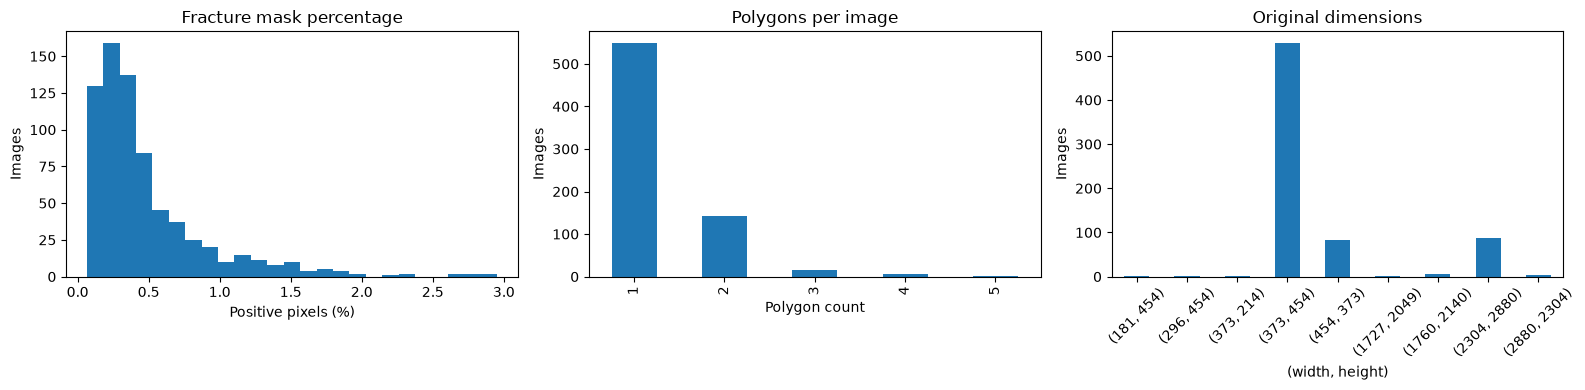

In [13]:
print({'annotated_images': len(baseline_validation_df), 'polygon_regions': int(baseline_validation_df.polygon_count.sum()), 'fracture_percent_min': baseline_validation_df.fracture_percent.min(), 'fracture_percent_max': baseline_validation_df.fracture_percent.max(), 'fracture_percent_median': baseline_validation_df.fracture_percent.median(), 'fracture_percent_mean': baseline_validation_df.fracture_percent.mean()})
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(baseline_validation_df.fracture_percent, bins=25); axes[0].set(title='Fracture mask percentage', xlabel='Positive pixels (%)', ylabel='Images')
baseline_validation_df.polygon_count.value_counts().sort_index().plot.bar(ax=axes[1]); axes[1].set(title='Polygons per image', xlabel='Polygon count', ylabel='Images')
baseline_validation_df.groupby(['width', 'height']).size().plot.bar(ax=axes[2]); axes[2].set(title='Original dimensions', xlabel='(width, height)', ylabel='Images'); axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

## 8. Image-level train/validation/test splits
Splits are saved and reused only when their IDs exactly cover the current validated annotated set. Polygons are never split independently.

In [14]:
baseline_manifest_columns = ['image_id', 'filename', 'image_path', 'mask_path', 'polygon_count']
baseline_all_ids = set(baseline_validation_df.image_id)
def baseline_valid_saved_splits():
    paths = {name: SPLIT_DIR / f'{name}.csv' for name in ['train', 'validation', 'test']}
    if not all(path.exists() for path in paths.values()): return None
    frames = {name: pd.read_csv(path) for name, path in paths.items()}
    ids = [set(frame.image_id) for frame in frames.values()]
    if set.union(*ids) != baseline_all_ids or sum(map(len, ids)) != len(baseline_all_ids) or len(set.union(*ids)) != sum(map(len, ids)): return None
    return frames
baseline_splits = baseline_valid_saved_splits()
if baseline_splits is None:
    split_ids, baseline_test_ids = train_test_split(sorted(baseline_all_ids), test_size=BASELINE_TEST_RATIO, random_state=BASELINE_SEED)
    baseline_train_ids, baseline_val_ids = train_test_split(split_ids, test_size=BASELINE_VAL_RATIO / (BASELINE_TRAIN_RATIO + BASELINE_VAL_RATIO), random_state=BASELINE_SEED)
    baseline_id_frames = {r.image_id: r for r in baseline_validation_df.itertuples()}
    baseline_splits = {'train': baseline_validation_df[baseline_validation_df.image_id.isin(baseline_train_ids)], 'validation': baseline_validation_df[baseline_validation_df.image_id.isin(baseline_val_ids)], 'test': baseline_validation_df[baseline_validation_df.image_id.isin(baseline_test_ids)]}
    for name, frame in baseline_splits.items(): frame[baseline_manifest_columns].to_csv(SPLIT_DIR / f'{name}.csv', index=False)
else:
    print('Reusing existing valid split manifests.')
if set(baseline_splits['train'].image_id) & set(baseline_splits['validation'].image_id) or set(baseline_splits['train'].image_id) & set(baseline_splits['test'].image_id) or set(baseline_splits['validation'].image_id) & set(baseline_splits['test'].image_id): raise RuntimeError('Split overlap detected.')
display(pd.DataFrame([{'split': name, 'images': len(frame), 'percent': 100 * len(frame) / len(baseline_validation_df)} for name, frame in baseline_splits.items()]))

Reusing existing valid split manifests.


,split,images,percent
0,train,499,69.790210
1,validation,108,15.104895
2,test,108,15.104895


## 9. Full-image preprocessing and baseline Dataset
Images use bilinear resizing and masks use nearest-neighbor resizing. Training-only horizontal flips and small rotations are applied identically to image and mask. Normalization statistics are calculated from the training split and cached in the experiment config.

In [15]:
def baseline_resize_and_pad(array, interpolation):
    source_height, source_width = array.shape[:2]
    scale = min(BASELINE_IMAGE_WIDTH / source_width, BASELINE_IMAGE_HEIGHT / source_height)
    resized_width = max(1, min(BASELINE_IMAGE_WIDTH, int(round(source_width * scale))))
    resized_height = max(1, min(BASELINE_IMAGE_HEIGHT, int(round(source_height * scale))))
    resized = cv2.resize(array, (resized_width, resized_height), interpolation=interpolation)
    pad_left = (BASELINE_IMAGE_WIDTH - resized_width) // 2
    pad_top = (BASELINE_IMAGE_HEIGHT - resized_height) // 2
    padded = np.zeros((BASELINE_IMAGE_HEIGHT, BASELINE_IMAGE_WIDTH), dtype=resized.dtype)
    padded[pad_top:pad_top + resized_height, pad_left:pad_left + resized_width] = resized
    geometry = {'source_width': source_width, 'source_height': source_height, 'scale': scale, 'resized_width': resized_width, 'resized_height': resized_height, 'pad_left': pad_left, 'pad_top': pad_top, 'target_width': BASELINE_IMAGE_WIDTH, 'target_height': BASELINE_IMAGE_HEIGHT}
    return padded, geometry

def baseline_training_stats(frame):
    values = []
    for path in frame.image_path:
        image = cv2.imread(path, cv2.IMREAD_GRAYSCALE); resized, _ = baseline_resize_and_pad(image, cv2.INTER_AREA); values.append(resized.astype(np.float32) / 255.0)
    pixels = np.concatenate([x.reshape(-1) for x in values]); return float(pixels.mean()), float(pixels.std() + 1e-6)
baseline_mean, baseline_std = baseline_training_stats(baseline_splits['train'])
BASELINE_CONFIG.update({'normalization_mean': baseline_mean, 'normalization_std': baseline_std})
BASELINE_CONFIG_PATH.write_text(json.dumps(BASELINE_CONFIG, indent=2))

class BaselineFracAtlasDataset(Dataset):
    def __init__(self, manifest, training=False): self.manifest, self.training = manifest.reset_index(drop=True), training
    def __len__(self): return len(self.manifest)
    def __getitem__(self, index):
        row = self.manifest.iloc[index]
        image = cv2.imread(row.image_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE)
        image, image_geometry = baseline_resize_and_pad(image, cv2.INTER_AREA); mask, mask_geometry = baseline_resize_and_pad(mask, cv2.INTER_NEAREST)
        if image_geometry != mask_geometry: raise RuntimeError(f'Image/mask preprocessing geometry mismatch for {row.image_id}')
        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(np.repeat(image[None], 3, axis=0)).float(); mask = torch.from_numpy((mask > 0).astype(np.float32)[None])
        if self.training:
            if torch.rand(()) < 0.5: image, mask = TF.hflip(image), TF.hflip(mask)
            angle = float(torch.empty(1).uniform_(-BASELINE_ROTATION_DEGREES, BASELINE_ROTATION_DEGREES))
            image = TF.rotate(image, angle, interpolation=InterpolationMode.BILINEAR, fill=0); mask = TF.rotate(mask, angle, interpolation=InterpolationMode.NEAREST, fill=0)
        image = (image - baseline_mean) / baseline_std; mask = (mask > 0.5).float()
        return image, mask, row.image_id

def baseline_loader_factory(batch_size=BASELINE_PHYSICAL_BATCH_SIZE, accumulation_steps=BASELINE_GRAD_ACCUMULATION_STEPS):
    generator = torch.Generator().manual_seed(BASELINE_SEED)
    common = {'num_workers': 0, 'pin_memory': DEVICE.type == 'cuda', 'persistent_workers': False}
    return {
        'train': DataLoader(BaselineFracAtlasDataset(baseline_splits['train'], True), batch_size=batch_size, shuffle=True, generator=generator, **common),
        'validation': DataLoader(BaselineFracAtlasDataset(baseline_splits['validation'], False), batch_size=batch_size, shuffle=False, **common),
        'test': DataLoader(BaselineFracAtlasDataset(baseline_splits['test'], False), batch_size=batch_size, shuffle=False, **common)}

baseline_loaders = baseline_loader_factory()
baseline_batch = next(iter(baseline_loaders['train']))
print('Image batch:', tuple(baseline_batch[0].shape), 'Mask batch:', tuple(baseline_batch[1].shape), 'IDs:', baseline_batch[2][:2])

Image batch: (2, 3, 640, 512) Mask batch: (2, 1, 640, 512) IDs: ('IMG0002602', 'IMG0003844')


## 10. Baseline Vanilla U-Net architecture
This architecture is deliberately baseline-specific and returns one-channel logits at the original spatial resolution.

In [20]:
class BaselineConvBlock(nn.Module):
    def __init__(self, input_channels, output_channels):
        super().__init__(); self.block = nn.Sequential(nn.Conv2d(input_channels, output_channels, 3, padding=1, bias=False), nn.BatchNorm2d(output_channels), nn.ReLU(inplace=True), nn.Conv2d(output_channels, output_channels, 3, padding=1, bias=False), nn.BatchNorm2d(output_channels), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class BaselineVanillaUNet(nn.Module):
    def __init__(self, input_channels=3, output_channels=1, channels=(16, 32, 64, 128, 256)):
        super().__init__(); self.encoders = nn.ModuleList(); self.pools = nn.ModuleList()
        current = input_channels
        for channel in channels[:-1]: self.encoders.append(BaselineConvBlock(current, channel)); self.pools.append(nn.MaxPool2d(2)); current = channel
        self.bottleneck = BaselineConvBlock(channels[-2], channels[-1])
        self.upconvs = nn.ModuleList(); self.decoders = nn.ModuleList()
        current = channels[-1]
        for channel in reversed(channels[:-1]): self.upconvs.append(nn.ConvTranspose2d(current, channel, 2, stride=2)); self.decoders.append(BaselineConvBlock(channel * 2, channel)); current = channel
        self.head = nn.Conv2d(channels[0], output_channels, 1)
    def forward(self, x):
        skips = []
        for encoder, pool in zip(self.encoders, self.pools): x = encoder(x); skips.append(x); x = pool(x)
        x = self.bottleneck(x)
        for upconv, decoder, skip in zip(self.upconvs, self.decoders, reversed(skips)):
            x = upconv(x)
            if x.shape[-2:] != skip.shape[-2:]: x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
            x = decoder(torch.cat([skip, x], dim=1))
        return self.head(x)

baseline_model = BaselineVanillaUNet().to(DEVICE)
baseline_dummy_output = baseline_model(torch.zeros(1, 3, BASELINE_IMAGE_HEIGHT, BASELINE_IMAGE_WIDTH, device=DEVICE))
assert tuple(baseline_dummy_output.shape) == (1, 1, BASELINE_IMAGE_HEIGHT, BASELINE_IMAGE_WIDTH)
baseline_parameters = sum(p.numel() for p in baseline_model.parameters()); baseline_trainable = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print('Output:', tuple(baseline_dummy_output.shape), 'Parameters:', baseline_parameters, 'Trainable:', baseline_trainable)

Output: (1, 1, 640, 512) Parameters: 1942577 Trainable: 1942577


## 11. Baseline losses, metrics, and checkpoint utilities
Dice handles empty masks explicitly: two empty masks score 1, while an empty target with non-empty prediction scores 0. Metrics consume probabilities before thresholding only where stated; reported segmentation metrics use thresholded masks.

In [24]:
def baseline_dice_score(logits, targets, threshold=None, smooth=1e-6):
    probabilities = torch.sigmoid(logits); predictions = (probabilities >= threshold).float() if threshold is not None else probabilities
    predictions, targets = predictions.flatten(1), targets.float().flatten(1); intersection = (predictions * targets).sum(1); denominator = predictions.sum(1) + targets.sum(1)
    score = (2 * intersection + smooth) / (denominator + smooth); empty = denominator == 0; return torch.where(empty, torch.ones_like(score), score).mean()
def baseline_iou_score(logits, targets, threshold=BASELINE_THRESHOLD, smooth=1e-6):
    predictions, targets = (torch.sigmoid(logits) >= threshold), targets.bool(); intersection = (predictions & targets).flatten(1).sum(1).float(); union = (predictions | targets).flatten(1).sum(1).float(); return torch.where(union == 0, torch.ones_like(union), (intersection + smooth) / (union + smooth)).mean()
def baseline_precision_score(logits, targets, threshold=BASELINE_THRESHOLD, smooth=1e-6):
    predictions, targets = (torch.sigmoid(logits) >= threshold), targets.bool(); tp = (predictions & targets).flatten(1).sum(1).float(); fp = (predictions & ~targets).flatten(1).sum(1).float(); return ((tp + smooth) / (tp + fp + smooth)).mean()
def baseline_recall_score(logits, targets, threshold=BASELINE_THRESHOLD, smooth=1e-6):
    predictions, targets = (torch.sigmoid(logits) >= threshold), targets.bool(); tp = (predictions & targets).flatten(1).sum(1).float(); fn = (~predictions & targets).flatten(1).sum(1).float(); return ((tp + smooth) / (tp + fn + smooth)).mean()
def baseline_combined_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets.float()); probabilities = torch.sigmoid(logits); intersection = (probabilities * targets).flatten(1).sum(1); dice_loss = 1 - ((2 * intersection + 1e-6) / (probabilities.flatten(1).sum(1) + targets.flatten(1).sum(1) + 1e-6)).mean(); return BASELINE_BCE_WEIGHT * bce + BASELINE_DICE_WEIGHT * dice_loss

BASELINE_LATEST_CHECKPOINT = CHECKPOINT_DIR / 'latest.pth'; BASELINE_BEST_CHECKPOINT = CHECKPOINT_DIR / 'best.pth'; BASELINE_HISTORY_PATH = HISTORY_DIR / 'vanilla_unet_history.json'
def baseline_atomic_torch_save(payload, path):
    temporary = path.with_suffix(path.suffix + '.tmp'); torch.save(payload, temporary); temporary.replace(path)
def baseline_rng_state(): return {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}
def baseline_restore_rng(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    cpu_state = state.get('torch')
    if cpu_state is not None:
        torch.set_rng_state(torch.as_tensor(cpu_state, dtype=torch.uint8, device='cpu').contiguous())
    cuda_state = state.get('cuda')
    if torch.cuda.is_available() and cuda_state is not None:
        torch.cuda.set_rng_state_all([torch.as_tensor(value, dtype=torch.uint8, device='cpu').contiguous() for value in cuda_state])

## 12. Training smoke test and resumable training
A forward/loss/backward/optimizer/AMP smoke test runs before training. Each epoch writes `latest.pth`; validation-Dice improvements write `best.pth`; history and status are updated after every epoch. Existing completed training is reused.

In [22]:
baseline_optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=BASELINE_LEARNING_RATE, weight_decay=BASELINE_WEIGHT_DECAY)
baseline_scaler = torch.amp.GradScaler("cuda" , enabled=BASELINE_AMP_ENABLED)
baseline_optimizer.zero_grad(set_to_none=True); smoke_images, smoke_masks, _ = baseline_batch; smoke_images, smoke_masks = smoke_images.to(DEVICE), smoke_masks.to(DEVICE)
with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=BASELINE_AMP_ENABLED): smoke_logits = baseline_model(smoke_images); smoke_loss = baseline_combined_loss(smoke_logits, smoke_masks)
baseline_scaler.scale(smoke_loss).backward(); baseline_scaler.step(baseline_optimizer); baseline_scaler.update(); baseline_optimizer.zero_grad(set_to_none=True)
print('Smoke test passed:', float(smoke_loss.detach().cpu()))
if torch.cuda.is_available(): print('Peak GPU memory MB:', round(torch.cuda.max_memory_allocated() / 2**20, 1))

def baseline_run_epoch(model, loader, optimizer=None, scaler=None, accumulation_steps=1):
    training = optimizer is not None; model.train(training); totals = {'loss': 0., 'dice': 0., 'iou': 0.}; count = 0
    if training: optimizer.zero_grad(set_to_none=True)
    for batch_index, (images, masks, _) in enumerate(loader):
        images, masks = images.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=BASELINE_AMP_ENABLED): logits = model(images); loss = baseline_combined_loss(logits, masks)
        if training:
            scaler.scale(loss / accumulation_steps).backward()
            if (batch_index + 1) % accumulation_steps == 0 or batch_index + 1 == len(loader): scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
        with torch.no_grad(): totals['loss'] += float(loss.detach()) * len(images); totals['dice'] += float(baseline_dice_score(logits.detach(), masks, BASELINE_THRESHOLD)) * len(images); totals['iou'] += float(baseline_iou_score(logits.detach(), masks)) * len(images)
        count += len(images)
    return {key: value / max(count, 1) for key, value in totals.items()}

def baseline_load_checkpoint(model, optimizer, scaler):
    if not BASELINE_LATEST_CHECKPOINT.exists(): return 0, [], 0.0, False
    checkpoint = torch.load(BASELINE_LATEST_CHECKPOINT, map_location=DEVICE, weights_only=False); model.load_state_dict(checkpoint['model']); optimizer.load_state_dict(checkpoint['optimizer']); scaler.load_state_dict(checkpoint['scaler']); baseline_restore_rng(checkpoint['rng'])
    return checkpoint['epoch'] + 1, checkpoint.get('history', []), checkpoint.get('best_val_dice', 0.0), True

def baseline_train():
    global baseline_model, baseline_optimizer, baseline_scaler, baseline_loaders
    baseline_model = BaselineVanillaUNet().to(DEVICE); baseline_optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=BASELINE_LEARNING_RATE, weight_decay=BASELINE_WEIGHT_DECAY); baseline_scaler = torch.cuda.amp.GradScaler(enabled=BASELINE_AMP_ENABLED)
    start_epoch, history, best_dice, resumed = baseline_load_checkpoint(baseline_model, baseline_optimizer, baseline_scaler)
    if start_epoch >= BASELINE_EPOCHS and BASELINE_BEST_CHECKPOINT.exists(): print('Training already complete; reusing checkpoint.'); return history
    batch_size, accumulation = BASELINE_PHYSICAL_BATCH_SIZE, BASELINE_GRAD_ACCUMULATION_STEPS
    for epoch in range(start_epoch, BASELINE_EPOCHS):
        try:
            baseline_loaders = baseline_loader_factory(batch_size, accumulation); started = time.time()
            train = baseline_run_epoch(baseline_model, baseline_loaders['train'], baseline_optimizer, baseline_scaler, accumulation); validation = baseline_run_epoch(baseline_model, baseline_loaders['validation'])
        except RuntimeError as error:
            if 'out of memory' not in str(error).lower() or batch_size == BASELINE_FALLBACK_BATCH_SIZE: raise
            if torch.cuda.is_available(): torch.cuda.empty_cache()
            batch_size, accumulation = BASELINE_FALLBACK_BATCH_SIZE, BASELINE_FALLBACK_ACCUMULATION_STEPS; print('CUDA OOM: retrying current epoch with physical batch size 1 and accumulation 4.'); continue
        row = {'epoch': epoch + 1, 'train_loss': train['loss'], 'val_loss': validation['loss'], 'train_dice': train['dice'], 'val_dice': validation['dice'], 'train_iou': train['iou'], 'val_iou': validation['iou'], 'learning_rate': baseline_optimizer.param_groups[0]['lr'], 'duration_seconds': time.time() - started, 'physical_batch_size': batch_size, 'accumulation_steps': accumulation}; history.append(row)
        improved = validation['dice'] > best_dice; best_dice = max(best_dice, validation['dice']); payload = {'epoch': epoch, 'model': baseline_model.state_dict(), 'optimizer': baseline_optimizer.state_dict(), 'scaler': baseline_scaler.state_dict(), 'history': history, 'best_val_dice': best_dice, 'config': BASELINE_CONFIG, 'rng': baseline_rng_state()}
        baseline_atomic_torch_save(payload, BASELINE_LATEST_CHECKPOINT);
        if improved: baseline_atomic_torch_save(payload, BASELINE_BEST_CHECKPOINT)
        BASELINE_HISTORY_PATH.write_text(json.dumps(history, indent=2)); BASELINE_STATUS_PATH.write_text(json.dumps({'status': 'TRAINING_IN_PROGRESS' if epoch + 1 < BASELINE_EPOCHS else 'TRAINING_COMPLETE', 'epoch': epoch + 1, 'best_val_dice': best_dice}, indent=2))
        print(f"Epoch {epoch + 1:02d}/{BASELINE_EPOCHS} | train loss {train['loss']:.4f} | val loss {validation['loss']:.4f} | val Dice {validation['dice']:.4f}")
    return history
baseline_history = baseline_train()

Smoke test passed: 0.8319540619850159
Peak GPU memory MB: 977.6
Training already complete; reusing checkpoint.


/tmp/ipykernel_2408/1541232016.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  baseline_model = BaselineVanillaUNet().to(DEVICE); baseline_optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=BASELINE_LEARNING_RATE, weight_decay=BASELINE_WEIGHT_DECAY); baseline_scaler = torch.cuda.amp.GradScaler(enabled=BASELINE_AMP_ENABLED)


## 13. Training curves
Curves are saved once and regenerated on reruns from the checkpoint history. Interpret convergence, overfitting, or underfitting from the observed curves.

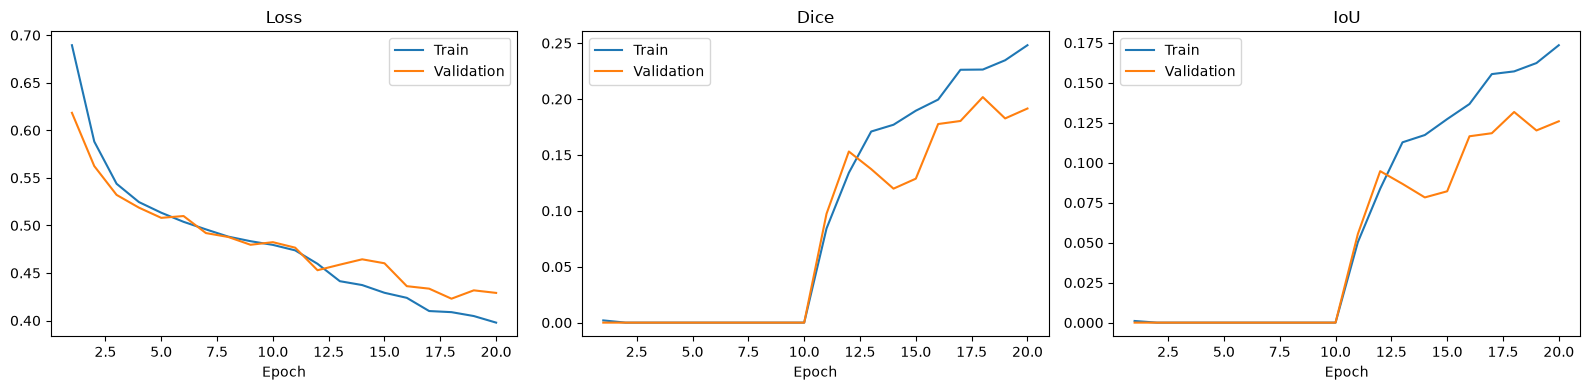

Inspect the train/validation gaps and trends above for convergence or overfitting.


In [35]:
baseline_history_df = pd.DataFrame(baseline_history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(baseline_history_df.epoch, baseline_history_df.train_loss, label='Train'); axes[0].plot(baseline_history_df.epoch, baseline_history_df.val_loss, label='Validation'); axes[0].set(title='Loss', xlabel='Epoch'); axes[0].legend()
axes[1].plot(baseline_history_df.epoch, baseline_history_df.train_dice, label='Train'); axes[1].plot(baseline_history_df.epoch, baseline_history_df.val_dice, label='Validation'); axes[1].set(title='Dice', xlabel='Epoch'); axes[1].legend()
axes[2].plot(baseline_history_df.epoch, baseline_history_df.train_iou, label='Train'); axes[2].plot(baseline_history_df.epoch, baseline_history_df.val_iou, label='Validation'); axes[2].set(title='IoU', xlabel='Epoch'); axes[2].legend()
plt.tight_layout(); fig.savefig(VIZ_DIR / 'training_curves' / 'vanilla_unet_training_curves.png', dpi=150); plt.show()
if len(baseline_history_df) > 1: print('Inspect the train/validation gaps and trends above for convergence or overfitting.')

## 14. Held-out test evaluation
The best validation-Dice checkpoint is loaded exactly once for test evaluation. Threshold `0.5` is fixed in configuration and is not tuned on the test set.

In [ ]:
from scipy.ndimage import binary_erosion, distance_transform_edt

def baseline_hd95(prediction, target):
    prediction = np.asarray(prediction, dtype=bool); target = np.asarray(target, dtype=bool)
    if prediction.shape != target.shape: raise ValueError(f'HD95 shape mismatch: {prediction.shape} != {target.shape}')
    if not prediction.any() and not target.any(): return 0.0
    if not prediction.any() or not target.any(): return float('inf')
    prediction_boundary = prediction & ~binary_erosion(prediction, border_value=0)
    target_boundary = target & ~binary_erosion(target, border_value=0)
    prediction_to_target = distance_transform_edt(~target_boundary)[prediction_boundary]
    target_to_prediction = distance_transform_edt(~prediction_boundary)[target_boundary]
    return float(np.percentile(np.concatenate([prediction_to_target, target_to_prediction]), 95))

def baseline_validate_evaluation_helpers():
    reference = np.zeros((16, 16), dtype=bool); reference[5:9, 5:9] = True
    shifted = np.zeros((16, 16), dtype=bool); shifted[5:9, 6:10] = True
    assert baseline_hd95(reference, reference) == 0.0
    assert baseline_hd95(np.zeros_like(reference), np.zeros_like(reference)) == 0.0
    assert np.isinf(baseline_hd95(reference, np.zeros_like(reference)))
    assert np.isinf(baseline_hd95(np.zeros_like(reference), reference))
    assert baseline_hd95(reference, shifted) > 0.0
    bce_check = nn.BCEWithLogitsLoss()(torch.zeros(2, 1, 4, 4), torch.ones(2, 1, 4, 4))
    assert torch.isclose(bce_check, torch.tensor(float(np.log(2.0))))

def baseline_evaluate_test():
    if not BASELINE_BEST_CHECKPOINT.is_file(): raise FileNotFoundError(f'Best checkpoint not found: {BASELINE_BEST_CHECKPOINT.resolve()}')
    test_frame = baseline_splits['test'].reset_index(drop=True)
    if len(test_frame) == 0: raise ValueError('The test split is empty.')
    if test_frame.image_id.duplicated().any(): raise ValueError('Test split contains duplicate image IDs.')
    missing_pairs = [str(path) for path in test_frame.image_path.tolist() + test_frame.mask_path.tolist() if not Path(path).is_file()]
    if missing_pairs: raise FileNotFoundError(f'Missing test image/mask files: {missing_pairs[:5]}')
    baseline_validate_evaluation_helpers()
    model = BaselineVanillaUNet().to(DEVICE)
    checkpoint = torch.load(BASELINE_BEST_CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint['model'], strict=True)
    model.eval(); bce_loss = nn.BCEWithLogitsLoss(reduction='none'); image_filename_by_id = dict(zip(test_frame.image_id, test_frame.image_path.map(lambda path: Path(path).name))); rows = []
    with torch.no_grad():
        for images, masks, ids in baseline_loader_factory()['test']:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            if images.shape[-2:] != masks.shape[-2:]: raise ValueError(f'Image/mask spatial shape mismatch: {images.shape} != {masks.shape}')
            if not torch.all((masks == 0) | (masks == 1)): raise ValueError('Test masks must contain only binary values 0 and 1.')
            logits = model(images); probabilities = torch.sigmoid(logits); predictions = (probabilities >= BASELINE_THRESHOLD).float()
            for index, image_id in enumerate(ids):
                logit = logits[index:index + 1]; mask = masks[index:index + 1]; prediction = predictions[index:index + 1]
                rows.append({'image_filename': image_filename_by_id[str(image_id)], 'image_id': str(image_id), 'dice': float(baseline_dice_score(logit, mask, BASELINE_THRESHOLD)), 'iou': float(baseline_iou_score(logit, mask)), 'precision': float(baseline_precision_score(logit, mask)), 'recall': float(baseline_recall_score(logit, mask)), 'hd95_pixels': baseline_hd95(prediction[0, 0].cpu().numpy(), mask[0, 0].cpu().numpy()), 'bce_loss': float(bce_loss(logit, mask).mean().item())})
    result = pd.DataFrame(rows)
    output_dir = OUTPUT_ROOT / 'evaluation'; output_dir.mkdir(parents=True, exist_ok=True)
    result.to_csv(output_dir / 'test_metrics.csv', index=False); result.to_csv(EVAL_DIR / 'vanilla_unet_per_image_metrics.csv', index=False)
    numeric_metrics = ['dice', 'iou', 'precision', 'recall', 'bce_loss']; aggregate = {metric: {'mean': float(result[metric].mean()), 'std': float(result[metric].std(ddof=0))} for metric in numeric_metrics}
    finite_hd95 = result.loc[np.isfinite(result.hd95_pixels), 'hd95_pixels']; infinite_hd95_count = int(np.isinf(result.hd95_pixels).sum())
    aggregate['hd95_pixels'] = {'mean': float(result.hd95_pixels.mean()) if infinite_hd95_count == 0 else None, 'std': float(result.hd95_pixels.std(ddof=0)) if infinite_hd95_count == 0 else None, 'finite_mean': float(finite_hd95.mean()) if len(finite_hd95) else None, 'finite_std': float(finite_hd95.std(ddof=0)) if len(finite_hd95) else None, 'infinite_count': infinite_hd95_count}
    aggregate.update({'test_images': len(result), 'checkpoint': str(BASELINE_BEST_CHECKPOINT), 'threshold': BASELINE_THRESHOLD, 'hd95_units': 'pixels'})
    (output_dir / 'test_metrics.json').write_text(json.dumps(aggregate, indent=2, allow_nan=False))
    summary_lines = ['FracAtlas Vanilla U-Net test evaluation', f'Checkpoint: {BASELINE_BEST_CHECKPOINT}', f'Test images: {len(result)}', f'HD95 infinite cases: {infinite_hd95_count}'] + [f'{metric}: mean={values["mean"]:.6f}, std={values["std"]:.6f}' for metric, values in aggregate.items() if isinstance(values, dict) and 'mean' in values and values['mean'] is not None] + [f'HD95 finite mean={aggregate["hd95_pixels"]["finite_mean"]}, finite std={aggregate["hd95_pixels"]["finite_std"]}']
    (output_dir / 'evaluation_summary.txt').write_text('\n'.join(summary_lines) + '\n')
    return model, result, aggregate

baseline_best_model, baseline_test_metrics, baseline_test_aggregate = baseline_evaluate_test()
baseline_test_summary = baseline_test_metrics[['dice', 'iou', 'precision', 'recall']].mean().to_dict(); display(pd.DataFrame([{'dice': baseline_test_summary['dice'], 'iou': baseline_test_summary['iou'], 'precision': baseline_test_summary['precision'], 'recall': baseline_test_summary['recall'], 'hd95_finite_mean_pixels': baseline_test_aggregate['hd95_pixels']['finite_mean'], 'hd95_finite_std_pixels': baseline_test_aggregate['hd95_pixels']['finite_std'], 'hd95_infinite_count': baseline_test_aggregate['hd95_pixels']['infinite_count'], 'bce_mean': baseline_test_aggregate['bce_loss']['mean'], 'bce_std': baseline_test_aggregate['bce_loss']['std']}]))
BASELINE_STATUS_PATH.write_text(json.dumps({'status': 'EVALUATION_COMPLETE', 'test_images': len(baseline_test_metrics)}, indent=2))

,dice,iou,precision,recall,hd95_finite_mean_pixels,hd95_finite_std_pixels,hd95_infinite_count,bce_mean,bce_std
0,0.235798,0.163175,0.285955,0.283308,158.991499,112.873602,5,0.033471,0.025247


59

## 15. Qualitative test predictions
These visualizations use held-out test images only and show the original resized X-ray, ground truth, prediction, and both overlays in the same coordinate system.

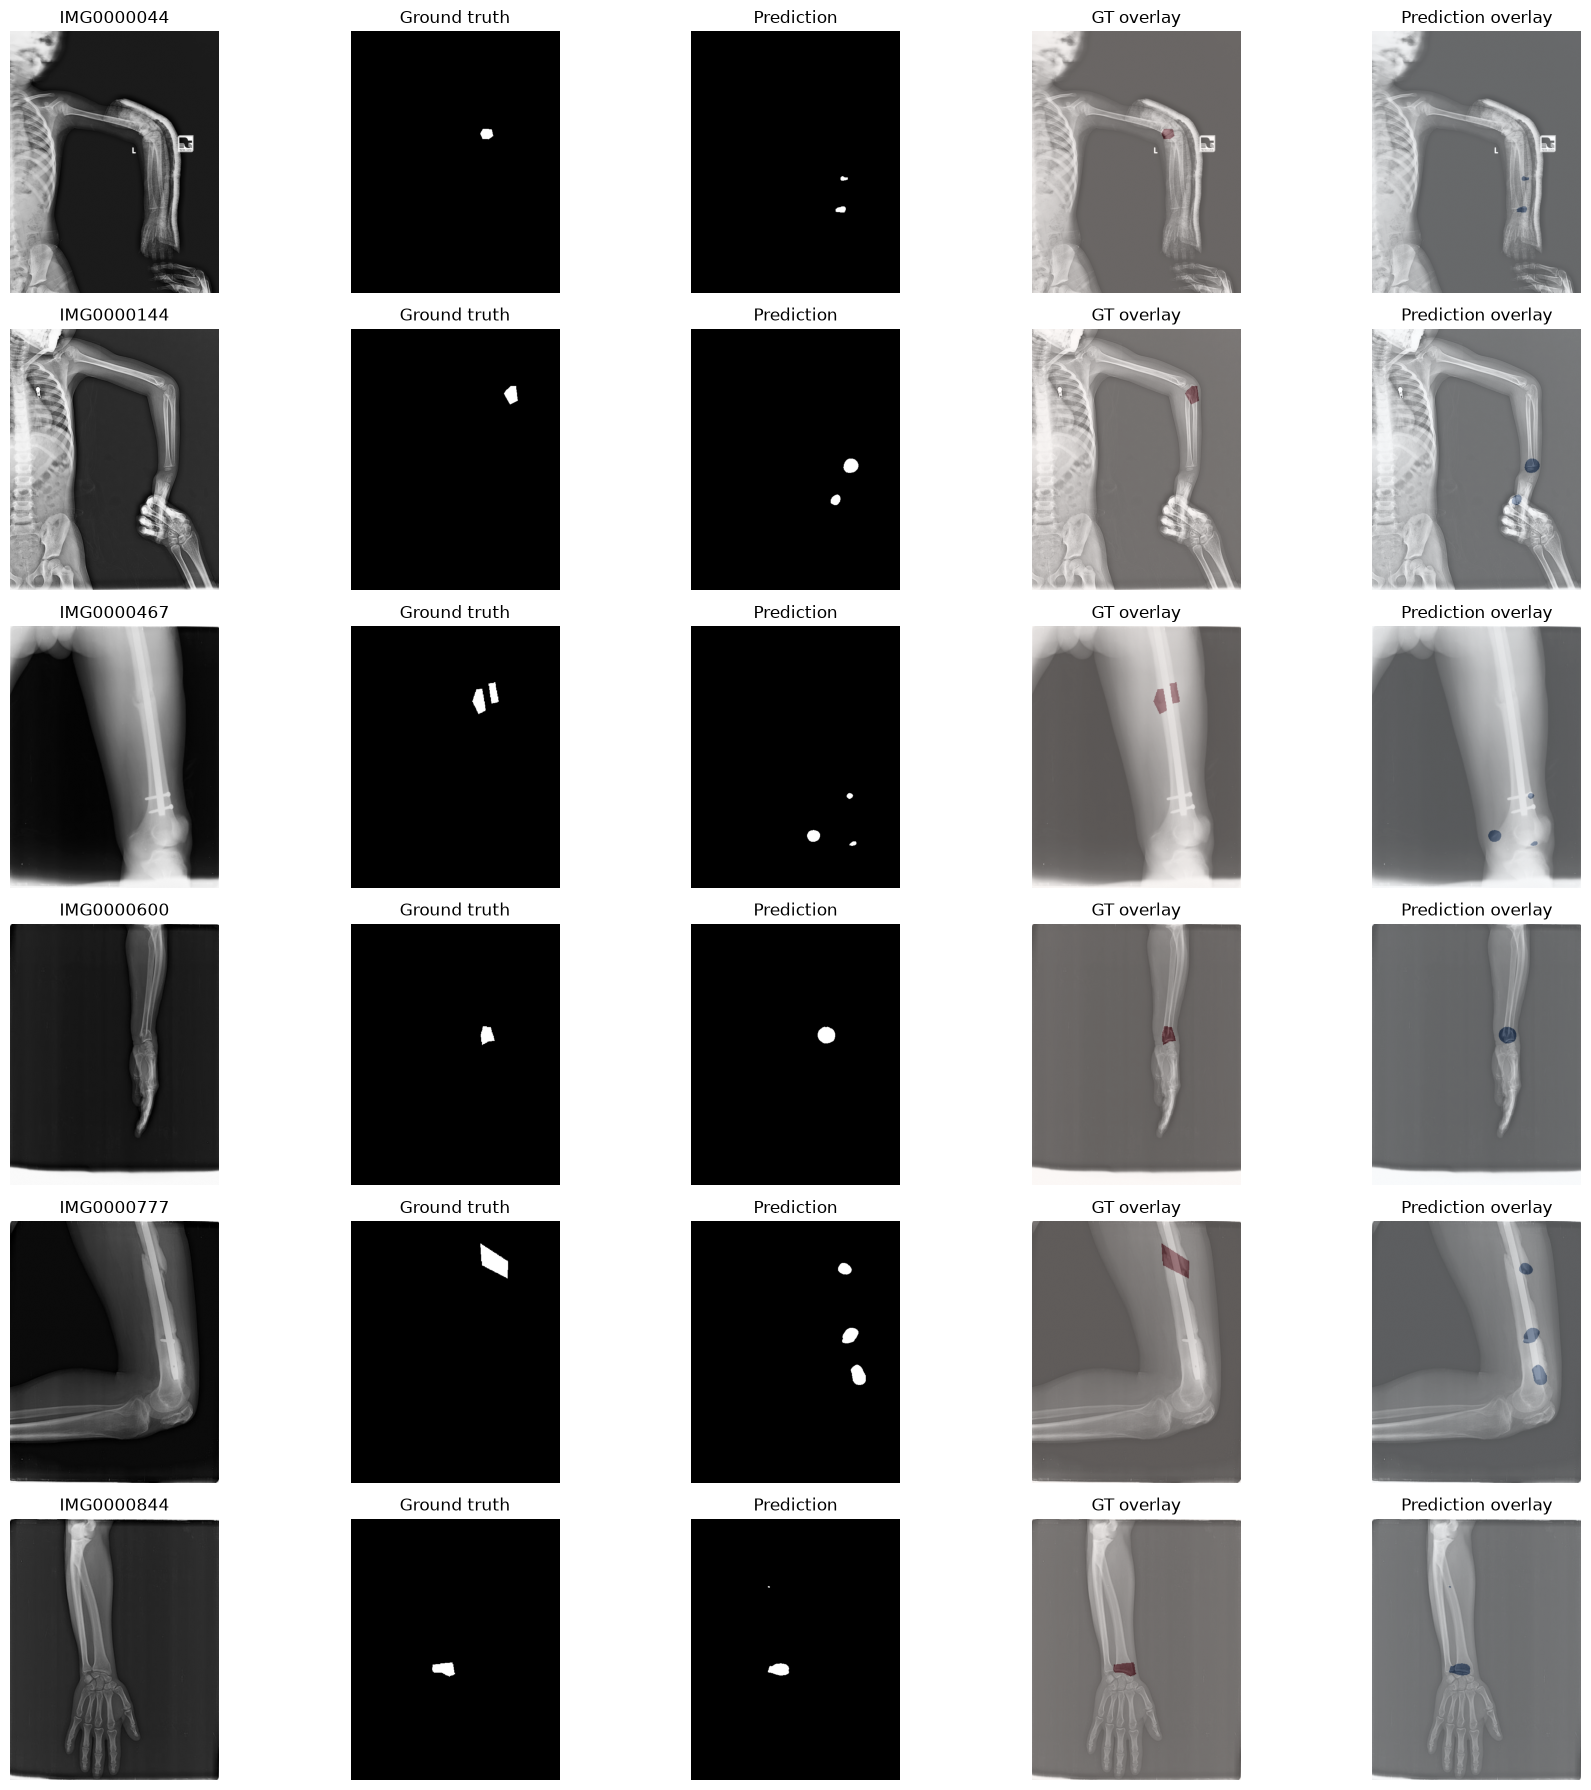

outputs/visualizations/vanilla_unet/test_predictions/vanilla_unet_test_predictions.png


In [ ]:
def baseline_show_test_predictions(model, frame, count=6):
    selected = frame.head(count).reset_index(drop=True); dataset = BaselineFracAtlasDataset(selected, False); fig, axes = plt.subplots(len(selected), 5, figsize=(18, max(3, 3 * len(selected)))); axes = np.atleast_2d(axes)
    model.eval()
    for row_index in range(len(selected)):
        image, mask, image_id = dataset[row_index]
        with torch.no_grad(): prediction = (torch.sigmoid(model(image[None].to(DEVICE)))[0, 0].cpu().numpy() >= BASELINE_THRESHOLD).astype(np.uint8)
        image_np = ((image[0].numpy() * baseline_std + baseline_mean) * 255).clip(0, 255)
        panels = [(image_np, 'X-ray', 'gray'), (mask[0].numpy(), 'Ground truth', 'gray'), (prediction, 'Prediction', 'gray')]
        axes[row_index, 0].imshow(image_np, cmap='gray'); axes[row_index, 0].set_title(str(image_id))
        axes[row_index, 1].imshow(mask[0], cmap='gray', vmin=0, vmax=1); axes[row_index, 1].set_title('Ground truth')
        axes[row_index, 2].imshow(prediction, cmap='gray', vmin=0, vmax=1); axes[row_index, 2].set_title('Prediction')
        axes[row_index, 3].imshow(image_np, cmap='gray'); axes[row_index, 3].imshow(mask[0], cmap='Reds', alpha=0.35, vmin=0, vmax=1); axes[row_index, 3].set_title('GT overlay')
        axes[row_index, 4].imshow(image_np, cmap='gray'); axes[row_index, 4].imshow(prediction, cmap='Blues', alpha=0.35, vmin=0, vmax=1); axes[row_index, 4].set_title('Prediction overlay')
        for axis in axes[row_index]: axis.axis('off')
    plt.tight_layout(); output_path = VIZ_DIR / 'test_predictions' / 'vanilla_unet_test_predictions.png'; fig.savefig(output_path, dpi=150); plt.show(); print(output_path)
baseline_show_test_predictions(baseline_best_model, baseline_splits['test'], count=min(6, len(baseline_splits['test'])))

## 16. Baseline experimental summary
The summary is written after evaluation and records the exact data, architecture, split, checkpoint, and test metrics used by this baseline.

In [ ]:
best_row = baseline_history_df.loc[baseline_history_df.val_dice.idxmax()] if len(baseline_history_df) else {}
baseline_summary = {'dataset': 'FracAtlas', 'experiment_name': 'vanilla_unet', 'annotated_images': len(baseline_validation_df), 'polygon_regions': int(baseline_validation_df.polygon_count.sum()), 'split_counts': {name: len(frame) for name, frame in baseline_splits.items()}, 'input_resolution_width_height': [BASELINE_IMAGE_WIDTH, BASELINE_IMAGE_HEIGHT], 'tensor_shape': [3, BASELINE_IMAGE_HEIGHT, BASELINE_IMAGE_WIDTH], 'architecture': 'Vanilla U-Net', 'parameters': baseline_parameters, 'trainable_parameters': baseline_trainable, 'best_validation_dice': float(best_row.val_dice) if len(baseline_history_df) else None, 'best_epoch': int(best_row.epoch) if len(baseline_history_df) else None, 'test_metrics': {key: float(value) for key, value in baseline_test_summary.items()}, 'training_duration_seconds': float(baseline_history_df.duration_seconds.sum()) if len(baseline_history_df) else None, 'peak_gpu_memory_mb': float(torch.cuda.max_memory_allocated() / 2**20) if torch.cuda.is_available() else None, 'checkpoint': str(BASELINE_BEST_CHECKPOINT), 'normalization': {'mean': baseline_mean, 'std': baseline_std}, 'shared_preprocessing_root': str(PREPROCESSING_ROOT)}
(EVAL_DIR / 'vanilla_unet_summary.json').write_text(json.dumps(baseline_summary, indent=2))
display(pd.DataFrame([baseline_summary]))
print('Artifacts:', OUTPUT_ROOT.resolve())

,dataset,experiment_name,annotated_images,polygon_regions,split_counts,input_resolution_width_height,tensor_shape,architecture,parameters,trainable_parameters,best_validation_dice,best_epoch,test_metrics,training_duration_seconds,peak_gpu_memory_mb,checkpoint,normalization,shared_preprocessing_root
0,FracAtlas,vanilla_unet,715,912,"{'train': 499, 'validation': 108, 'test': 108}","[512, 640]","[3, 640, 512]",Vanilla U-Net,1942577,1942577,0.201711,18,"{'dice': 0.23579770526910965, 'iou': 0.1631749...",635.731101,1399.284668,outputs/checkpoints/vanilla_unet/best.pth,"{'mean': 0.19784314930438995, 'std': 0.1994355...",outputs/preprocessing


Artifacts: /home/theChosenOne/Projects/ml-project/outputs


## 17. ResNet18 U-Net experiments
The two ResNet18 U-Net approaches are modular and are launched independently. Execute only one launch cell at a time; defining the training function does not start training. The frozen-encoder approach keeps the encoder frozen for all epochs. The two-phase approach freezes it for the first two epochs, then unfreezes it with differential learning rates (encoder `1e-5`, decoder/head `1e-4`).

### 17.1 Task 2 configuration

In [40]:
import torchvision
from torchvision.models import ResNet18_Weights

TASK2_ROOT = OUTPUT_ROOT / 'checkpoints' / 'resnet18_unet'
TASK2_HISTORY_ROOT = OUTPUT_ROOT / 'histories' / 'resnet18_unet'
TASK2_CONFIG_ROOT = OUTPUT_ROOT / 'experiment_configs' / 'resnet18_unet'
TASK2_EVAL_ROOT = OUTPUT_ROOT / 'evaluation' / 'resnet18_unet'
for path in (TASK2_ROOT, TASK2_HISTORY_ROOT, TASK2_CONFIG_ROOT, TASK2_EVAL_ROOT): path.mkdir(parents=True, exist_ok=True)
TASK2_EPOCHS = BASELINE_EPOCHS
TASK2_FREEZE_EPOCHS = 2
TASK2_ENCODER_LR = 1e-5
TASK2_DECODER_LR = 1e-4
TASK2_THRESHOLD = BASELINE_THRESHOLD
TASK2_USE_PRETRAINED_ENCODER = True
TASK2_IMAGE_WIDTH, TASK2_IMAGE_HEIGHT = BASELINE_IMAGE_WIDTH, BASELINE_IMAGE_HEIGHT
TASK2_CONFIG = {'architecture': 'ResNet18 U-Net', 'image_width': TASK2_IMAGE_WIDTH, 'image_height': TASK2_IMAGE_HEIGHT, 'epochs': TASK2_EPOCHS, 'freeze_epochs': TASK2_FREEZE_EPOCHS, 'encoder_learning_rate': TASK2_ENCODER_LR, 'decoder_learning_rate': TASK2_DECODER_LR, 'threshold': TASK2_THRESHOLD, 'pretrained_encoder': TASK2_USE_PRETRAINED_ENCODER, 'normalization_mean': baseline_mean, 'normalization_std': baseline_std}
TASK2_CONFIG_PATH = TASK2_CONFIG_ROOT / 'resnet18_unet.json'
TASK2_CONFIG_PATH.write_text(json.dumps(TASK2_CONFIG, indent=2))


327

### 17.2 ResNet18 U-Net architecture

In [26]:
class Task2DecoderBlock(nn.Module):
    def __init__(self, input_channels, skip_channels, output_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(input_channels, output_channels, 2, 2)
        self.block = nn.Sequential(nn.Conv2d(output_channels + skip_channels, output_channels, 3, padding=1, bias=False), nn.BatchNorm2d(output_channels), nn.ReLU(inplace=True), nn.Conv2d(output_channels, output_channels, 3, padding=1, bias=False), nn.BatchNorm2d(output_channels), nn.ReLU(inplace=True))
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]: x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        return self.block(torch.cat((x, skip), dim=1))

class ResNet18UNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        encoder = torchvision.models.resnet18(weights=weights)
        self.encoder_stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.encoder_pool = encoder.maxpool
        self.encoder1, self.encoder2 = encoder.layer1, encoder.layer2
        self.encoder3, self.encoder4 = encoder.layer3, encoder.layer4
        self.center = nn.Conv2d(512, 512, 1)
        self.decoder4 = Task2DecoderBlock(512, 256, 256)
        self.decoder3 = Task2DecoderBlock(256, 128, 128)
        self.decoder2 = Task2DecoderBlock(128, 64, 64)
        self.decoder1 = Task2DecoderBlock(64, 64, 32)
        self.head_up = nn.ConvTranspose2d(32, 16, 2, 2)
        self.head = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        stem = self.encoder_stem(x)
        x1 = self.encoder1(self.encoder_pool(stem))
        x2 = self.encoder2(x1)
        x3 = self.encoder3(x2)
        x4 = self.encoder4(x3)
        x = self.center(x4)
        x = self.decoder4(x, x3); x = self.decoder3(x, x2); x = self.decoder2(x, x1); x = self.decoder1(x, stem)
        return self.head(self.head_up(x))

task2_model_check = ResNet18UNet(pretrained=False).to(DEVICE)
assert tuple(task2_model_check(torch.zeros(1, 3, TASK2_IMAGE_HEIGHT, TASK2_IMAGE_WIDTH, device=DEVICE)).shape) == (1, 1, TASK2_IMAGE_HEIGHT, TASK2_IMAGE_WIDTH)
TASK2_PARAMETERS = sum(p.numel() for p in task2_model_check.parameters())
print('Task 2 parameters:', TASK2_PARAMETERS)
del task2_model_check


Task 2 parameters: 14499265


### 17.3 Losses, optimizer groups, and checkpoint helpers

In [27]:
def task2_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets.float())
    probabilities = torch.sigmoid(logits); intersection = (probabilities * targets).flatten(1).sum(1)
    dice = ((2 * intersection + 1e-6) / (probabilities.flatten(1).sum(1) + targets.flatten(1).sum(1) + 1e-6)).mean()
    return 0.5 * bce + 0.5 * (1 - dice)

def task2_set_encoder_trainable(model, trainable):
    for module in (model.encoder_stem, model.encoder1, model.encoder2, model.encoder3, model.encoder4):
        for parameter in module.parameters(): parameter.requires_grad = trainable

def task2_optimizer(model, encoder_trainable):
    encoder_parameters = list(model.encoder_stem.parameters()) + list(model.encoder1.parameters()) + list(model.encoder2.parameters()) + list(model.encoder3.parameters()) + list(model.encoder4.parameters())
    encoder_ids = {id(parameter) for parameter in encoder_parameters}
    decoder_parameters = [parameter for parameter in model.parameters() if id(parameter) not in encoder_ids]
    groups = [{'params': decoder_parameters, 'lr': TASK2_DECODER_LR}]
    if encoder_trainable: groups.insert(0, {'params': encoder_parameters, 'lr': TASK2_ENCODER_LR})
    return torch.optim.AdamW(groups, weight_decay=BASELINE_WEIGHT_DECAY)

def task2_atomic_save(payload, path):
    temporary = path.with_suffix('.tmp'); torch.save(payload, temporary); temporary.replace(path)


### 17.4 Modular training function
This cell defines training only. It does not launch either experiment.

In [28]:
def train_resnet18_unet(approach='frozen_encoder'):
    if approach not in {'frozen_encoder', 'two_phase'}: raise ValueError(f'Unknown approach: {approach}')
    model = ResNet18UNet(pretrained=TASK2_USE_PRETRAINED_ENCODER).to(DEVICE)
    encoder_trainable = False; task2_set_encoder_trainable(model, encoder_trainable); optimizer = task2_optimizer(model, encoder_trainable)
    scaler = torch.amp.GradScaler('cuda', enabled=BASELINE_AMP_ENABLED); history = []; best_dice = -1.0; started_total = time.time()
    checkpoint_dir = TASK2_ROOT / approach; checkpoint_dir.mkdir(parents=True, exist_ok=True)
    for epoch in range(TASK2_EPOCHS):
        if approach == 'two_phase' and epoch == TASK2_FREEZE_EPOCHS:
            encoder_trainable = True; task2_set_encoder_trainable(model, True); optimizer = task2_optimizer(model, True)
        epoch_start = time.time(); model.train();
        if not encoder_trainable:
            for module in (model.encoder_stem, model.encoder_pool, model.encoder1, model.encoder2, model.encoder3, model.encoder4): module.eval()
        totals = {'loss': 0.0, 'dice': 0.0}; count = 0
        for images, masks, _ in baseline_loader_factory()['train']:
            images, masks = images.to(DEVICE), masks.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=BASELINE_AMP_ENABLED): logits = model(images); loss = task2_loss(logits, masks)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            with torch.no_grad(): totals['loss'] += float(loss) * len(images); totals['dice'] += float(baseline_dice_score(logits, masks, TASK2_THRESHOLD)) * len(images)
            count += len(images)
        model.eval(); val = baseline_run_epoch(model, baseline_loader_factory()['validation'])
        row = {'epoch': epoch + 1, 'phase': 'frozen_encoder' if not encoder_trainable else 'fine_tuning', 'train_loss': totals['loss'] / count, 'train_dice': totals['dice'] / count, 'val_loss': val['loss'], 'val_dice': val['dice'], 'duration_seconds': time.time() - epoch_start, 'encoder_trainable': encoder_trainable}; history.append(row)
        payload = {'epoch': epoch, 'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(), 'history': history, 'best_val_dice': max(best_dice, val['dice']), 'config': {**TASK2_CONFIG, 'approach': approach}, 'training_seconds': time.time() - started_total}
        task2_atomic_save(payload, checkpoint_dir / 'latest.pth')
        if val['dice'] > best_dice: best_dice = val['dice']; task2_atomic_save(payload, checkpoint_dir / 'best.pth')
        print(f'{approach} epoch {epoch + 1:02d}/{TASK2_EPOCHS} | phase={row["phase"]} | val Dice={val["dice"]:.4f}')
    history_path = TASK2_HISTORY_ROOT / f'{approach}_history.json'; history_path.write_text(json.dumps(history, indent=2))
    return model, pd.DataFrame(history), checkpoint_dir / 'best.pth'


### 17.5 Approach A launch — permanently frozen encoder
Run this cell independently when you want the permanently frozen experiment. It does not launch Approach B.

In [29]:
TASK2_FROZEN_MODEL, TASK2_FROZEN_HISTORY, TASK2_FROZEN_CHECKPOINT = train_resnet18_unet('frozen_encoder')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/theChosenOne/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 18.7MB/s]


frozen_encoder epoch 01/20 | phase=frozen_encoder | val Dice=0.0060
frozen_encoder epoch 02/20 | phase=frozen_encoder | val Dice=0.0000
frozen_encoder epoch 03/20 | phase=frozen_encoder | val Dice=0.0000
frozen_encoder epoch 04/20 | phase=frozen_encoder | val Dice=0.0000
frozen_encoder epoch 05/20 | phase=frozen_encoder | val Dice=0.0000
frozen_encoder epoch 06/20 | phase=frozen_encoder | val Dice=0.0000
frozen_encoder epoch 07/20 | phase=frozen_encoder | val Dice=0.3343
frozen_encoder epoch 08/20 | phase=frozen_encoder | val Dice=0.3840
frozen_encoder epoch 09/20 | phase=frozen_encoder | val Dice=0.4029
frozen_encoder epoch 10/20 | phase=frozen_encoder | val Dice=0.3794
frozen_encoder epoch 11/20 | phase=frozen_encoder | val Dice=0.4223
frozen_encoder epoch 12/20 | phase=frozen_encoder | val Dice=0.3762
frozen_encoder epoch 13/20 | phase=frozen_encoder | val Dice=0.4262
frozen_encoder epoch 14/20 | phase=frozen_encoder | val Dice=0.4105
frozen_encoder epoch 15/20 | phase=frozen_encode

### 17.6 Approach B launch — two-phase freeze then fine-tune
Run this cell independently when you want the two-phase experiment. It does not launch Approach A.

In [30]:
TASK2_TWO_PHASE_MODEL, TASK2_TWO_PHASE_HISTORY, TASK2_TWO_PHASE_CHECKPOINT = train_resnet18_unet('two_phase')


two_phase epoch 01/20 | phase=frozen_encoder | val Dice=0.2313
two_phase epoch 02/20 | phase=frozen_encoder | val Dice=0.2814
two_phase epoch 03/20 | phase=fine_tuning | val Dice=0.3077
two_phase epoch 04/20 | phase=fine_tuning | val Dice=0.3546
two_phase epoch 05/20 | phase=fine_tuning | val Dice=0.3063
two_phase epoch 06/20 | phase=fine_tuning | val Dice=0.3580
two_phase epoch 07/20 | phase=fine_tuning | val Dice=0.3689
two_phase epoch 08/20 | phase=fine_tuning | val Dice=0.3106
two_phase epoch 09/20 | phase=fine_tuning | val Dice=0.3551
two_phase epoch 10/20 | phase=fine_tuning | val Dice=0.3851
two_phase epoch 11/20 | phase=fine_tuning | val Dice=0.3549
two_phase epoch 12/20 | phase=fine_tuning | val Dice=0.3303
two_phase epoch 13/20 | phase=fine_tuning | val Dice=0.3562
two_phase epoch 14/20 | phase=fine_tuning | val Dice=0.3198
two_phase epoch 15/20 | phase=fine_tuning | val Dice=0.3811
two_phase epoch 16/20 | phase=fine_tuning | val Dice=0.3578
two_phase epoch 17/20 | phase=fine

## 18. Extended test evaluation and direct comparison
Evaluation uses the selected best checkpoint, the frozen validation threshold, original image coordinates, and the same test images. Empty/empty masks have HD95 0 pixels; exactly one empty mask has infinite HD95 and is reported as an edge case.

In [31]:
from scipy.ndimage import binary_erosion, distance_transform_edt

def extended_hd95(prediction, target):
    prediction, target = np.asarray(prediction, bool), np.asarray(target, bool)
    if not prediction.any() and not target.any(): return 0.0
    if not prediction.any() or not target.any(): return float('inf')
    structure = np.ones((3, 3), dtype=bool); ps = prediction & ~binary_erosion(prediction, structure=structure, border_value=0); ts = target & ~binary_erosion(target, structure=structure, border_value=0)
    return float(np.percentile(np.concatenate((distance_transform_edt(~ts)[ps], distance_transform_edt(~ps)[ts])), 95))

def extended_original_prediction(prediction, image_path):
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE); h, w = image.shape; th, tw = prediction.shape; scale = min(tw / w, th / h); rw, rh = max(1, round(w * scale)), max(1, round(h * scale)); left, top = (tw - rw) // 2, (th - rh) // 2
    return cv2.resize(prediction[top:top + rh, left:left + rw].astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)

def extended_pixel_metrics(prediction, target):
    tp = np.logical_and(prediction, target).sum(); fp = np.logical_and(prediction, ~target).sum(); fn = np.logical_and(~prediction, target).sum(); total = 2 * tp + fp + fn
    return {'dice': 1.0 if total == 0 else 2 * tp / total, 'iou': 1.0 if tp + fp + fn == 0 else tp / (tp + fp + fn), 'precision': 1.0 if tp + fp == 0 else tp / (tp + fp), 'recall': 1.0 if tp + fn == 0 else tp / (tp + fn)}


### 18.1 Evaluation implementation and saved artifacts

In [48]:
def evaluate_task2(model, checkpoint, approach, split_name='test'):
    payload = torch.load(checkpoint, map_location=DEVICE, weights_only=False); model.load_state_dict(payload['model'], strict=True); model.to(DEVICE).eval(); bce = nn.BCEWithLogitsLoss(reduction='none'); rows = []; start_all = time.time()
    frame = baseline_splits[split_name].reset_index(drop=True)
    with torch.no_grad():
        for images, masks, ids in baseline_loader_factory()[split_name]:
            logits = model(images.to(DEVICE)); predictions = torch.sigmoid(logits) >= TASK2_THRESHOLD
            for i, image_id in enumerate(ids):
                row = frame.loc[frame.image_id.astype(str) == str(image_id)].iloc[0]; target = cv2.imread(str(row.mask_path), cv2.IMREAD_GRAYSCALE) > 0; prediction = extended_original_prediction(predictions[i, 0].cpu().numpy(), row.image_path); metrics = extended_pixel_metrics(prediction, target)
                rows.append({'image_filename': Path(row.image_path).name, 'image_id': str(image_id), **metrics, 'hd95': extended_hd95(prediction, target), 'bce_loss': float(bce(logits[i:i + 1], masks[i:i + 1].to(DEVICE)).mean().cpu()), 'empty_prediction': not prediction.any(), 'empty_ground_truth': not target.any()})
    result = pd.DataFrame(rows); finite = result.loc[np.isfinite(result.hd95), 'hd95']; summary = {'approach': approach, 'split': split_name, 'checkpoint': str(checkpoint), 'evaluated_images': len(result), 'valid_hd95_cases': len(finite), 'empty_mask_edge_cases': int((result.empty_prediction | result.empty_ground_truth).sum()), 'hd95_units': 'original image pixels', 'empty_mask_convention': 'both empty=0; exactly one empty=inf', 'hd95': {key: (float(getattr(finite, key)()) if len(finite) else None) for key in ('mean', 'std', 'median', 'min', 'max')}, 'bce_loss': {'mean': float(result.bce_loss.mean()), 'std': float(result.bce_loss.std(ddof=0)), 'aggregate_image_averaged': float(result.bce_loss.mean())}, 'metrics': {key: {'mean': float(result[key].mean()), 'std': float(result[key].std(ddof=0))} for key in ('dice', 'iou', 'precision', 'recall')}, 'parameters': sum(p.numel() for p in model.parameters()), 'inference_seconds_per_image': (time.time() - start_all) / max(len(result), 1)}
    approach_eval_root = TASK2_EVAL_ROOT / approach / ('' if split_name == 'test' else split_name); approach_eval_root.mkdir(parents=True, exist_ok=True); result.to_csv(approach_eval_root / 'resnet18_unet_per_image_metrics.csv', index=False); (approach_eval_root / 'resnet18_unet_summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False)); return result, summary


### 18.2 Evaluation launch
Select one trained approach before running this cell; evaluation is separate from training and does not tune the test threshold.

In [43]:
TASK2_EVALUATION_APPROACH = 'two_phase'
TASK2_EVALUATION_CHECKPOINT = TASK2_ROOT / TASK2_EVALUATION_APPROACH / 'best.pth'
TASK2_EVALUATION_RESULT, TASK2_EVALUATION_SUMMARY = evaluate_task2(ResNet18UNet(pretrained=False), TASK2_EVALUATION_CHECKPOINT, TASK2_EVALUATION_APPROACH)


## 19. Final research results summary

In [36]:
baseline_supplementary = None
if BASELINE_BEST_CHECKPOINT.is_file():
    baseline_supplementary = {'architecture': 'Vanilla U-Net', 'parameters': baseline_parameters, 'training_time_seconds': float(baseline_history_df.duration_seconds.sum()) if len(baseline_history_df) else None, 'original_artifact': str(BASELINE_BEST_CHECKPOINT)}
final_summary = {'task2': TASK2_EVALUATION_SUMMARY if 'TASK2_EVALUATION_SUMMARY' in globals() else None, 'task1': baseline_supplementary, 'interpretation': 'Compare measured Dice/IoU/precision/recall, HD95, and BCE only when both summaries are available. Lower HD95 indicates better boundary localization; lower BCE indicates better pixel-wise prediction.'}
(OUTPUT_ROOT / 'evaluation' / 'resnet18_unet_final_summary.json').write_text(json.dumps(final_summary, indent=2, allow_nan=False)); display(pd.DataFrame([final_summary]))


,task2,task1,interpretation
0,"{'approach': 'two_phase', 'checkpoint': 'outpu...","{'architecture': 'Vanilla U-Net', 'parameters'...","Compare measured Dice/IoU/precision/recall, HD..."


### 20.1 Frozen-encoder evaluation
This evaluation is separate from the two-phase evaluation and does not retrain either approach.

In [42]:
TASK2_FROZEN_EVAL_RESULT, TASK2_FROZEN_EVAL_SUMMARY = evaluate_task2(ResNet18UNet(pretrained=False), TASK2_ROOT / 'frozen_encoder' / 'best.pth', 'frozen_encoder')


## 20. Task 2 sample predictions and measured metrics
This section is separate from the baseline visualization. It displays sample X-rays, ground-truth masks, and predictions for both Task 2 approaches, alongside the unmodified measured metrics loaded from each approach's evaluation CSV.


Task 2 approach: frozen_encoder, split: test


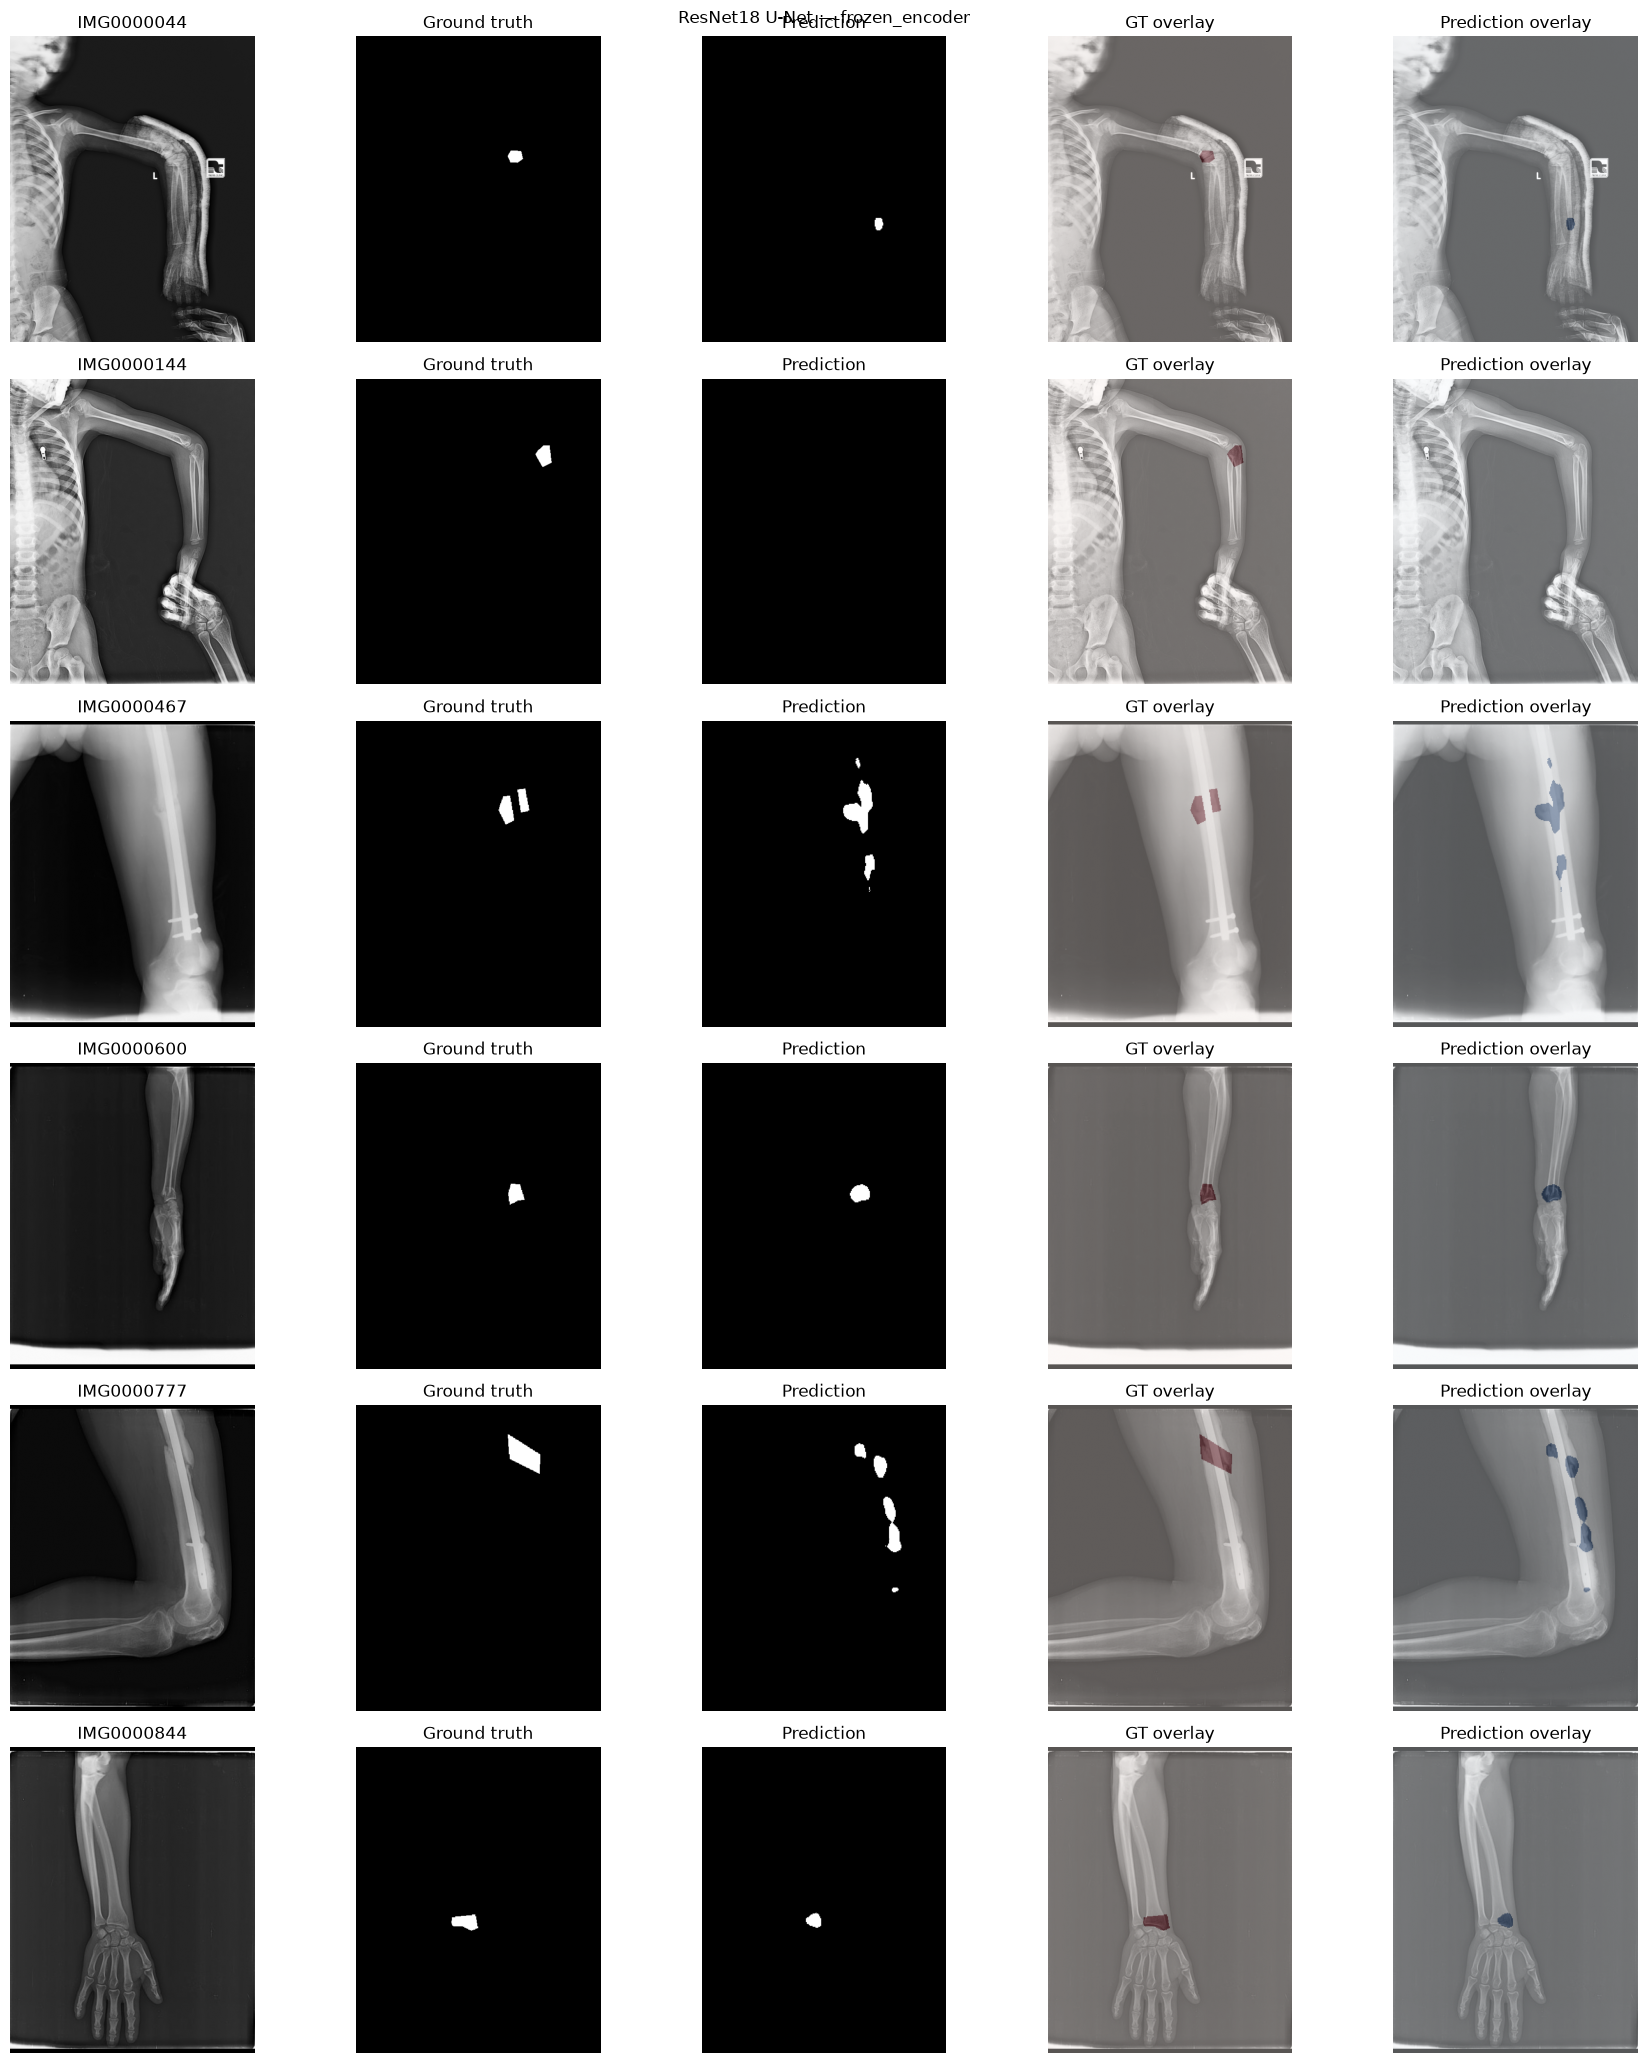


Task 2 approach: two_phase, split: test


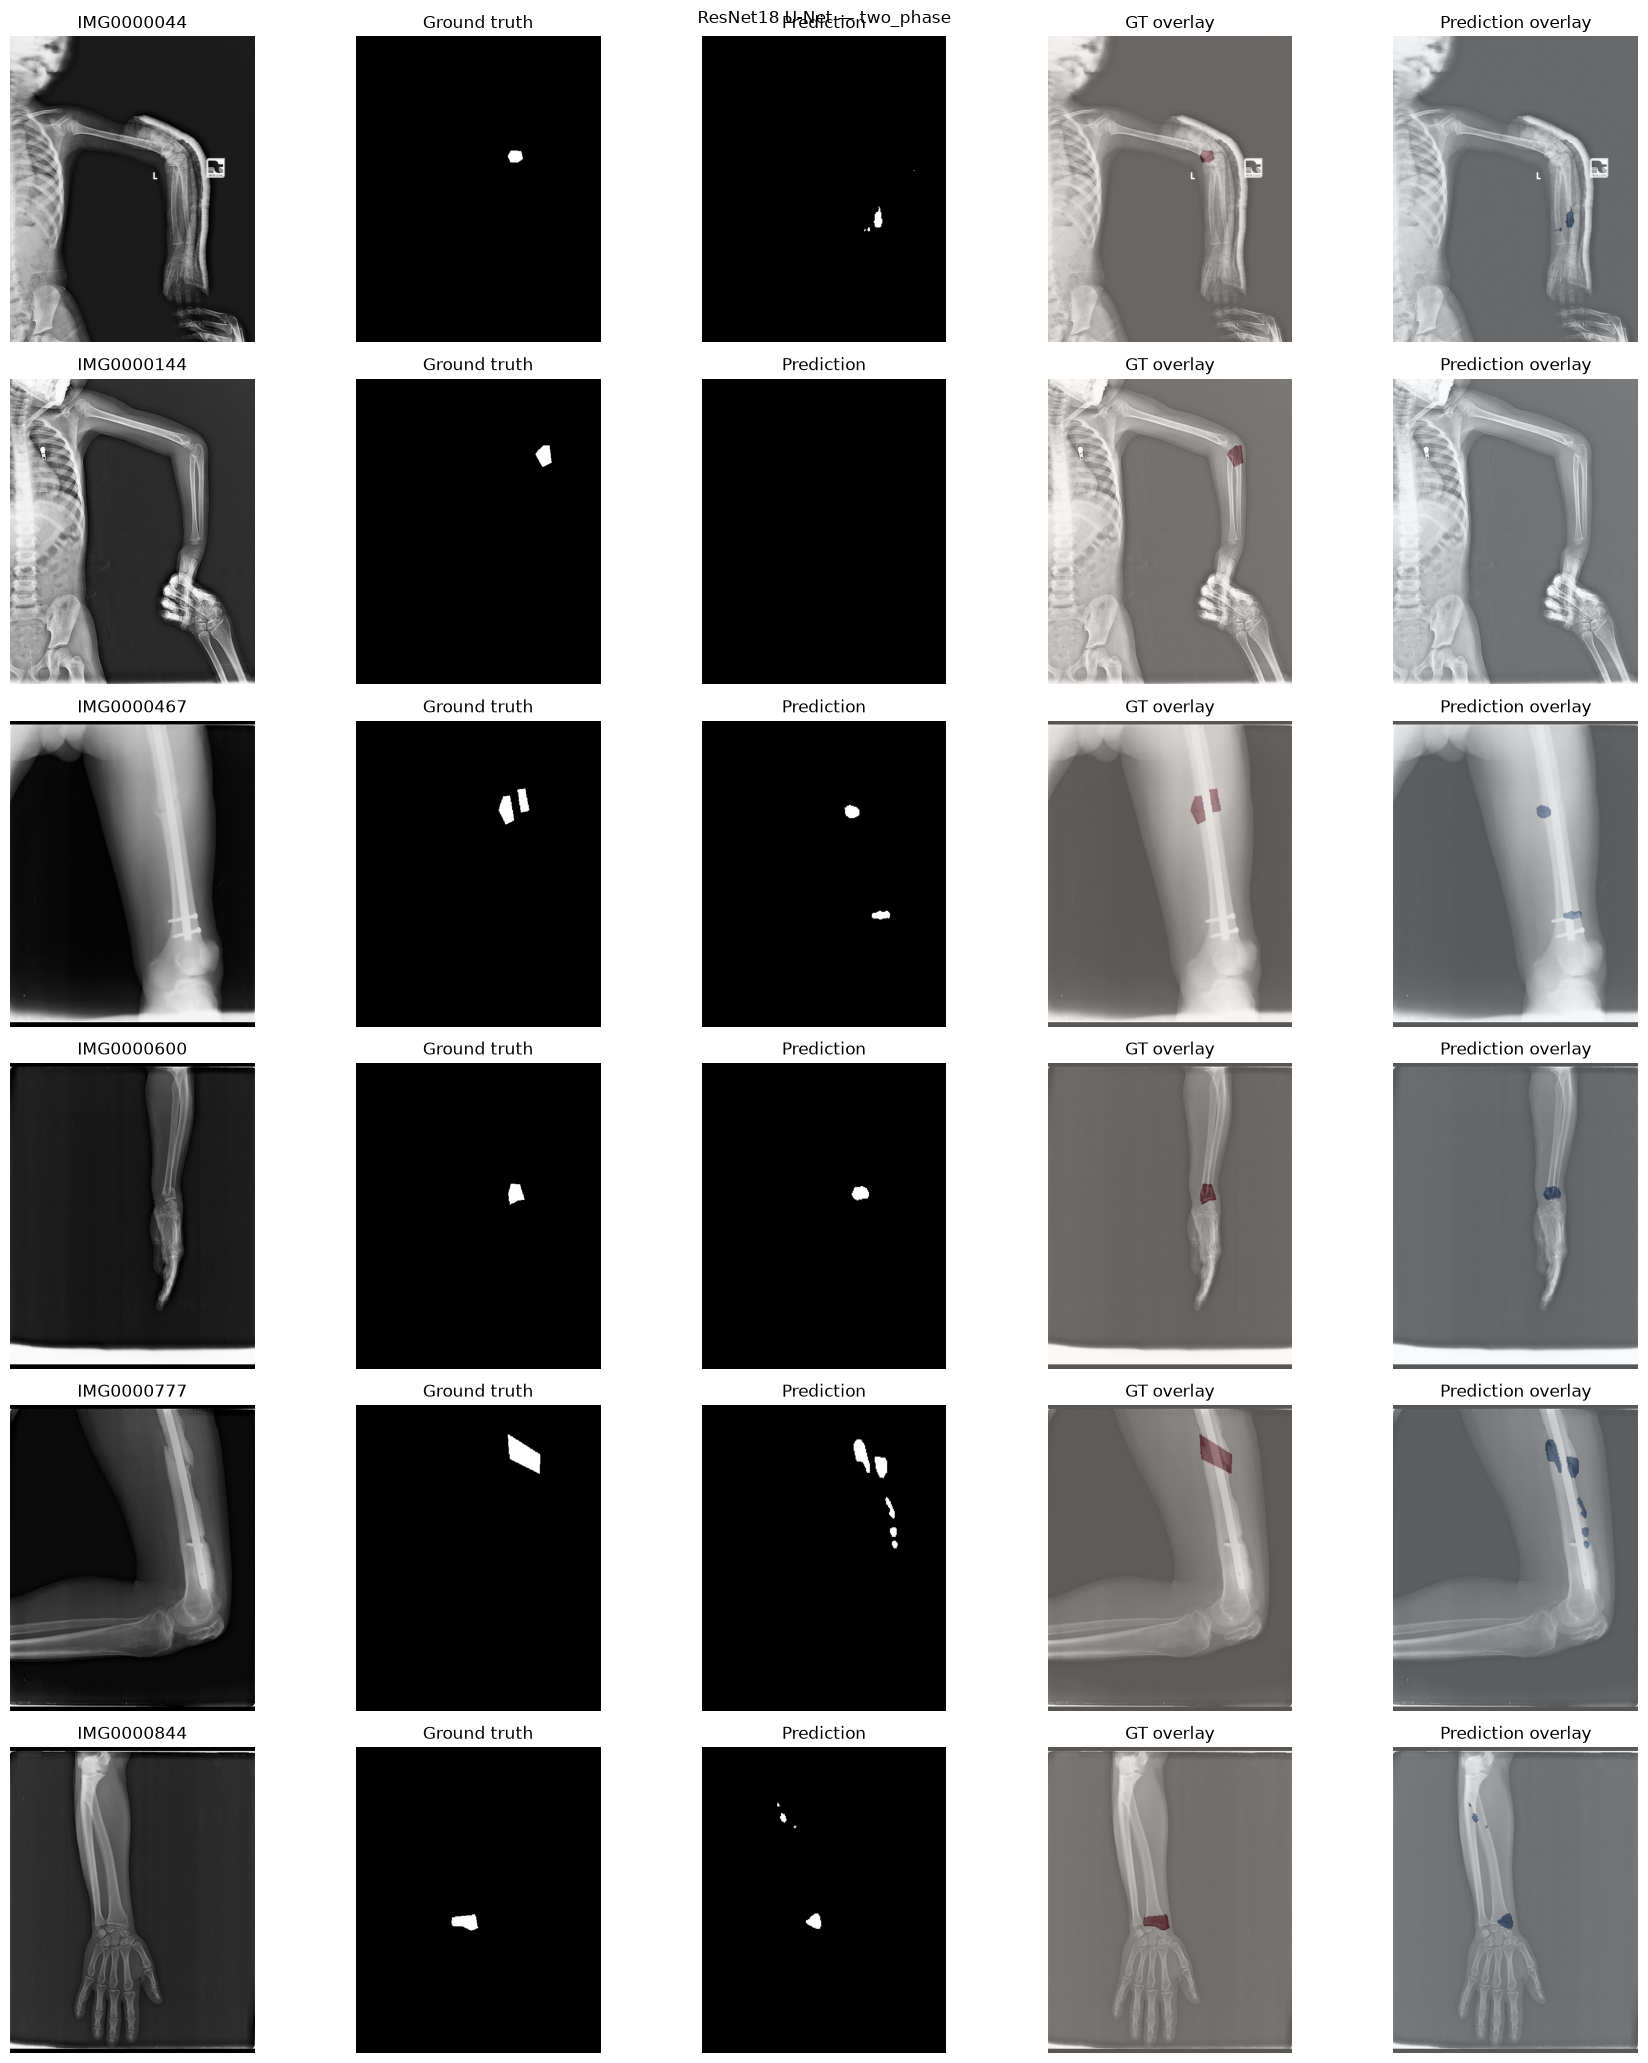

In [55]:
def display_task2_approach_samples(approach, split_name='test', count=6):
    """Display Task 2 samples and print measured per-image metrics."""
    split_root = TASK2_EVAL_ROOT / approach / ('' if split_name == 'test' else split_name)
    metrics_path = split_root / 'resnet18_unet_per_image_metrics.csv'
    summary_path = split_root / 'resnet18_unet_summary.json'
    checkpoint = TASK2_ROOT / approach / 'best.pth'
    if not metrics_path.is_file() or not summary_path.is_file() or not checkpoint.is_file():
        print(f'{approach}: unavailable; required checkpoint or evaluation CSV is missing.')
        return None
    metrics = pd.read_csv(metrics_path).head(count)
    model = ResNet18UNet(pretrained=False).to(DEVICE)
    payload = torch.load(checkpoint, map_location=DEVICE, weights_only=False)
    model.load_state_dict(payload['model'], strict=True); model.eval()
    selected = baseline_splits['test'].copy()
    selected = selected[selected.image_id.astype(str).isin(metrics.image_id.astype(str))].head(count).reset_index(drop=True)
    dataset = BaselineFracAtlasDataset(selected, False)
    fig, axes = plt.subplots(len(selected), 5, figsize=(18, max(4, 3.5 * len(selected))))
    axes = np.atleast_2d(axes)
    saved_summary = json.loads(summary_path.read_text())
    print(f"\nTask 2 approach: {approach}, split: {saved_summary.get('split', split_name)}")
    for row_index in range(len(selected)):
        image, mask, image_id = dataset[row_index]
        with torch.no_grad():
            logits = model(image[None].to(DEVICE))
            prediction = (torch.sigmoid(logits)[0, 0].cpu().numpy() >= TASK2_THRESHOLD).astype(np.uint8)
        image_np = ((image[0].numpy() * baseline_std + baseline_mean) * 255).clip(0, 255)
        metric = metrics.loc[metrics.image_id.astype(str) == str(image_id)].iloc[0]
        axes[row_index, 0].imshow(image_np, cmap='gray'); axes[row_index, 0].set_title(str(image_id))
        axes[row_index, 1].imshow(mask[0], cmap='gray', vmin=0, vmax=1); axes[row_index, 1].set_title('Ground truth')
        axes[row_index, 2].imshow(prediction, cmap='gray', vmin=0, vmax=1); axes[row_index, 2].set_title('Prediction')
        axes[row_index, 3].imshow(image_np, cmap='gray'); axes[row_index, 3].imshow(mask[0], cmap='Reds', alpha=0.35, vmin=0, vmax=1); axes[row_index, 3].set_title('GT overlay')
        axes[row_index, 4].imshow(image_np, cmap='gray'); axes[row_index, 4].imshow(prediction, cmap='Blues', alpha=0.35, vmin=0, vmax=1); axes[row_index, 4].set_title('Prediction overlay')
        for axis in axes[row_index]: axis.axis('off')
    plt.suptitle(f'ResNet18 U-Net — {approach}')
    plt.tight_layout(); plt.show()
    return metrics

# Execute independently; neither call modifies the other approach.
task2_frozen_sample_metrics = display_task2_approach_samples('frozen_encoder', split_name='test', count=6)
task2_two_phase_sample_metrics = display_task2_approach_samples('two_phase', split_name='test', count=6)


## 21. Task 2 validation-set metrics
Validation metrics are computed separately from the frozen validation split. They are not test metrics and are not used to tune the test threshold.

In [49]:
TASK2_FROZEN_VALIDATION_RESULT, TASK2_FROZEN_VALIDATION_SUMMARY = evaluate_task2(ResNet18UNet(pretrained=False), TASK2_ROOT / 'frozen_encoder' / 'best.pth', 'frozen_encoder', split_name='validation')
TASK2_TWO_PHASE_VALIDATION_RESULT, TASK2_TWO_PHASE_VALIDATION_SUMMARY = evaluate_task2(ResNet18UNet(pretrained=False), TASK2_ROOT / 'two_phase' / 'best.pth', 'two_phase', split_name='validation')


In [58]:
def display_task2_validation_metrics(approaches=('frozen_encoder', 'two_phase')):
    rows = []
    for approach in approaches:
        summary = load_task2_saved_summary(approach, 'validation')
        if summary is None:
            rows.append({'approach': approach, 'status': 'unavailable'})
            continue
        rows.append({'approach': approach, 'split': summary['split'], 'images': summary['evaluated_images'], 'dice_mean_std': f"{summary['metrics']['dice']['mean']:.4f} +/- {summary['metrics']['dice']['std']:.4f}", 'iou_mean_std': f"{summary['metrics']['iou']['mean']:.4f} +/- {summary['metrics']['iou']['std']:.4f}", 'precision_mean_std': f"{summary['metrics']['precision']['mean']:.4f} +/- {summary['metrics']['precision']['std']:.4f}", 'recall_mean_std': f"{summary['metrics']['recall']['mean']:.4f} +/- {summary['metrics']['recall']['std']:.4f}", 'hd95_mean_std_pixels': f"{summary['hd95']['mean']} +/- {summary['hd95']['std']}", 'bce_mean_std': f"{summary['bce_loss']['mean']:.6f} +/- {summary['bce_loss']['std']:.6f}"})
    return pd.DataFrame(rows)

task2_validation_metrics = display_task2_validation_metrics()
display(task2_validation_metrics)


,approach,split,images,dice_mean_std,iou_mean_std,precision_mean_std,recall_mean_std,hd95_mean_std_pixels,bce_mean_std
0,frozen_encoder,validation,108,0.5019 +/- 0.2830,0.4168 +/- 0.2316,0.5815 +/- 0.3182,0.5829 +/- 0.3353,102.88434268601998 +/- 231.49293958441046,0.022676 +/- 0.021663
1,two_phase,validation,108,0.4324 +/- 0.3179,0.3750 +/- 0.2593,0.6205 +/- 0.3442,0.4020 +/- 0.3439,86.26364318834747 +/- 212.47430315818465,0.031396 +/- 0.038741


In [56]:
def load_task2_saved_summary(approach, split_name='test'):
    split_root = TASK2_EVAL_ROOT / approach / ('' if split_name == 'test' else split_name)
    summary_path = split_root / 'resnet18_unet_summary.json'
    if not summary_path.is_file(): return None
    return json.loads(summary_path.read_text())

def display_task2_test_set_metrics(approaches=('frozen_encoder', 'two_phase')):
    """Display aggregate test-set metrics loaded from saved JSON summaries."""
    rows = []
    for approach in approaches:
        summary = load_task2_saved_summary(approach, 'test')
        if summary is None:
            rows.append({'approach': approach, 'status': 'unavailable'})
            continue
        row = {'approach': approach, 'status': 'measured', 'images': summary['evaluated_images'], 'dice_mean_std': f"{summary['metrics']['dice']['mean']:.4f} +/- {summary['metrics']['dice']['std']:.4f}", 'iou_mean_std': f"{summary['metrics']['iou']['mean']:.4f} +/- {summary['metrics']['iou']['std']:.4f}", 'precision_mean_std': f"{summary['metrics']['precision']['mean']:.4f} +/- {summary['metrics']['precision']['std']:.4f}", 'recall_mean_std': f"{summary['metrics']['recall']['mean']:.4f} +/- {summary['metrics']['recall']['std']:.4f}", 'hd95_mean_std_pixels': f"{summary['hd95']['mean']} +/- {summary['hd95']['std']}", 'bce_mean_std': f"{summary['bce_loss']['mean']:.6f} +/- {summary['bce_loss']['std']:.6f}"}
        rows.append(row)
    display(pd.DataFrame(rows))
    return pd.DataFrame(rows)

task2_test_set_metrics = display_task2_test_set_metrics()


,approach,status,images,dice_mean_std,iou_mean_std,precision_mean_std,recall_mean_std,hd95_mean_std_pixels,bce_mean_std
0,frozen_encoder,measured,108,0.4868 +/- 0.2778,0.4144 +/- 0.2359,0.6193 +/- 0.2971,0.5985 +/- 0.3430,70.60664730341905 +/- 111.64564737622926,0.019201 +/- 0.017192
1,two_phase,measured,108,0.4579 +/- 0.3117,0.3498 +/- 0.2643,0.6970 +/- 0.3046,0.4427 +/- 0.3296,56.02243967725693 +/- 85.90141123722482,0.024495 +/- 0.024458


## Frozen-encoder ResNet18 U-Net with CLAHE

This independent experiment applies CLAHE to grayscale radiographs, expands the result to three channels, and trains a separately initialized frozen-encoder ResNet18 U-Net. Existing cells, checkpoints, masks, split manifests, and baseline results are read-only inputs.

In [141]:
from pathlib import Path

import csv

import hashlib

import json

import random

import time

import cv2

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

import torch

from PIL import Image

from torch import nn

from torch.utils.data import DataLoader, Dataset

from torchvision.transforms import InterpolationMode

from torchvision.transforms import functional as TF

clahe_project_root = Path.cwd()

clahe_output_root = clahe_project_root / "outputs"

clahe_preprocess_root = clahe_output_root / "preprocessing" / "clahe"

clahe_image_root = clahe_preprocess_root / "images"

clahe_checkpoint_root = clahe_output_root / "checkpoints" / "resnet_unet_with_clahe"

clahe_history_root = clahe_output_root / "histories" / "resnet_unet_with_clahe"

clahe_evaluation_root = clahe_output_root / "evaluation" / "resnet_unet_with_clahe"

clahe_config_root = clahe_output_root / "experiment_configs"

clahe_visual_root = clahe_output_root / "visualizations"

clahe_benchmark_root = clahe_visual_root / "benchmarks"

clahe_preprocess_visual_root = clahe_visual_root / "clahe_preprocessing"

clahe_model_visual_root = clahe_visual_root / "resnet_unet_with_clahe"


In [142]:
for clahe_path in (clahe_image_root, clahe_checkpoint_root / "resume",
                   clahe_history_root, clahe_evaluation_root / "validation",
                   clahe_config_root, clahe_preprocess_visual_root,
                   clahe_model_visual_root, clahe_benchmark_root):
    clahe_path.mkdir(parents=True, exist_ok=True)


In [143]:
clahe_source_config_path = clahe_output_root / "experiment_configs" / "resnet18_unet" / "resnet18_unet.json"


In [144]:
if not clahe_source_config_path.is_file():
    raise FileNotFoundError(f"Frozen-encoder source configuration is missing: {clahe_source_config_path}")


In [145]:
clahe_mode_root = clahe_checkpoint_root
clahe_mode_history_root = clahe_history_root
clahe_mode_evaluation_root = clahe_evaluation_root
clahe_modes = {
    "frozen_encoder": {
        "encoder_trainable": False,
        "freeze_epochs": int(clahe_source_config["epochs"]),
        "encoder_learning_rate": 0.0,
        "decoder_learning_rate": float(clahe_source_config["decoder_learning_rate"]),
    },
    "two_phase": {
        "encoder_trainable": True,
        "freeze_epochs": int(clahe_source_config["freeze_epochs"]),
        "encoder_learning_rate": float(clahe_source_config["encoder_learning_rate"]),
        "decoder_learning_rate": float(clahe_source_config["decoder_learning_rate"]),
    },
}
for clahe_mode, clahe_mode_config in clahe_modes.items():
    clahe_mode_config["checkpoint_root"] = clahe_mode_root / clahe_mode
    clahe_mode_config["history_root"] = clahe_mode_history_root / clahe_mode
    clahe_mode_config["evaluation_root"] = clahe_mode_evaluation_root / clahe_mode
    for clahe_mode_path in (clahe_mode_config["checkpoint_root"] / "resume",
                            clahe_mode_config["history_root"],
                            clahe_mode_config["evaluation_root"] / "validation"):
        clahe_mode_path.mkdir(parents=True, exist_ok=True)

clahe_weight_decay = 1e-4
clahe_config = {
    **clahe_source_config,
    "experiment_name": "resnet_unet_with_clahe",
    "architecture": "ResNet18 U-Net",
    "preprocessing": {"clipLimit": 2.0, "tileGridSize": [8, 8], "channels": 3},
    "weight_decay": clahe_weight_decay,
    "physical_batch_size": 2,
    "gradient_accumulation_steps": 2,
    "num_workers": 0,
    "modes": {
        mode: {key: value for key, value in mode_config.items()
               if key not in {"checkpoint_root", "history_root", "evaluation_root"}}
        for mode, mode_config in clahe_modes.items()
    },
    "checkpoint_root": str(clahe_mode_root),
    "history_root": str(clahe_mode_history_root),
    "evaluation_root": str(clahe_mode_evaluation_root),
}
clahe_config_path = clahe_config_root / "resnet_unet_with_clahe.json"
clahe_config_json = json.dumps(clahe_config, indent=2)
if clahe_config_path.exists() and clahe_config_path.read_text() != clahe_config_json:
    clahe_config_path = clahe_config_root / "resnet_unet_with_clahe_v2.json"
if not clahe_config_path.exists():
    clahe_config_path.write_text(clahe_config_json)


In [149]:
while clahe_config_path.exists() and clahe_config_path.read_text() != clahe_config_json:
    clahe_config_version = clahe_config_path.stem.rsplit("_v", 1)
    clahe_version_number = int(clahe_config_version[1]) + 1 if len(clahe_config_version) == 2 and clahe_config_version[1].isdigit() else 2
    clahe_config_path = clahe_config_root / f"resnet_unet_with_clahe_v{clahe_version_number}.json"


In [150]:
if not clahe_config_path.exists():
    clahe_config_path.write_text(clahe_config_json)


In [151]:
clahe_split_root = clahe_output_root / "preprocessing" / "splits"

clahe_splits = {}


In [152]:
for clahe_split_name in ("train", "validation", "test"):
    clahe_split_path = clahe_split_root / f"{clahe_split_name}.csv"
    if not clahe_split_path.is_file():
        raise FileNotFoundError(f"Read-only split manifest is missing: {clahe_split_path}")
    clahe_splits[clahe_split_name] = pd.read_csv(clahe_split_path)
    if clahe_splits[clahe_split_name].image_id.duplicated().any():
        raise ValueError(f"{clahe_split_name} contains duplicate image IDs")


In [153]:
def clahe_resolve_path(value):
    path = Path(str(value))
    return path if path.is_absolute() else clahe_project_root / path


In [154]:
def clahe_clahe_image(source_path):
    image = cv2.imread(str(source_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Unable to read grayscale image: {source_path}")
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image)


In [155]:
def clahe_prepare_clahe_images():
    rows = []
    seen = set()
    for frame in clahe_splits.values():
        for row in frame.itertuples(index=False):
            image_id = str(row.image_id)
            if image_id in seen:
                continue
            seen.add(image_id)
            source = clahe_resolve_path(row.image_path)
            destination = clahe_image_root / Path(str(row.filename)).name
            source_image = cv2.imread(str(source), cv2.IMREAD_GRAYSCALE)
            if source_image is None:
                raise FileNotFoundError(f"Unable to read source image: {source}")
            if destination.exists():
                enhanced = cv2.imread(str(destination), cv2.IMREAD_GRAYSCALE)
                if enhanced is None or enhanced.shape != source_image.shape:
                    raise ValueError(f"Existing CLAHE image is invalid: {destination}")
            else:
                enhanced = clahe_clahe_image(source)
                if not cv2.imwrite(str(destination), enhanced):
                    raise OSError(f"Unable to write CLAHE image: {destination}")
            rows.append({
                "image_id": image_id,
                "filename": Path(str(row.filename)).name,
                "source_shape": list(source_image.shape),
                "clahe_shape": list(enhanced.shape),
                "source_mean": float(source_image.mean()),
                "clahe_mean": float(enhanced.mean()),
                "source_std": float(source_image.std()),
                "clahe_std": float(enhanced.std()),
            })
    return rows


In [156]:
clahe_preprocessing_rows = clahe_prepare_clahe_images()

clahe_preprocessing_stats = {
    "image_count": len(clahe_preprocessing_rows),
    "clipLimit": 2.0,
    "tileGridSize": [8, 8],
    "source_channels": 1,
    "output_channels": 3,
    "preserved_filenames": True,
    "preserved_spatial_dimensions": all(r["source_shape"] == r["clahe_shape"] for r in clahe_preprocessing_rows),
    "mean_source_intensity": float(np.mean([r["source_mean"] for r in clahe_preprocessing_rows])),
    "mean_clahe_intensity": float(np.mean([r["clahe_mean"] for r in clahe_preprocessing_rows])),
    "mean_source_std": float(np.mean([r["source_std"] for r in clahe_preprocessing_rows])),
    "mean_clahe_std": float(np.mean([r["clahe_std"] for r in clahe_preprocessing_rows])),
}

clahe_config_preprocess_path = clahe_preprocess_root / "clahe_config.json"

clahe_stats_path = clahe_preprocess_root / "preprocessing_statistics.json"


In [158]:
for clahe_json_path, clahe_payload in (
    (clahe_config_preprocess_path, {"clipLimit": 2.0, "tileGridSize": [8, 8], "input": "grayscale", "output": "three identical channels"}),
    (clahe_stats_path, clahe_preprocessing_stats),
):
    clahe_text = json.dumps(clahe_payload, indent=2)
    while clahe_json_path.exists() and clahe_json_path.read_text() != clahe_text:
        clahe_version_parts = clahe_json_path.stem.rsplit("_v", 1)
        clahe_version_number = int(clahe_version_parts[1]) + 1 if len(clahe_version_parts) == 2 and clahe_version_parts[1].isdigit() else 2
        clahe_json_path = clahe_json_path.with_name(f"{clahe_version_parts[0]}_v{clahe_version_number}{clahe_json_path.suffix}")
    if not clahe_json_path.exists():
        clahe_json_path.write_text(clahe_text)


In [159]:
def clahe_resize_and_pad(array, interpolation):
    source_height, source_width = array.shape[:2]
    scale = min(clahe_config["image_width"] / source_width, clahe_config["image_height"] / source_height)
    resized_width = max(1, min(clahe_config["image_width"], round(source_width * scale)))
    resized_height = max(1, min(clahe_config["image_height"], round(source_height * scale)))
    resized = cv2.resize(array, (resized_width, resized_height), interpolation=interpolation)
    pad_left = (clahe_config["image_width"] - resized_width) // 2
    pad_top = (clahe_config["image_height"] - resized_height) // 2
    padded = np.zeros((clahe_config["image_height"], clahe_config["image_width"]), dtype=resized.dtype)
    padded[pad_top:pad_top + resized_height, pad_left:pad_left + resized_width] = resized
    return padded, {"source_width": source_width, "source_height": source_height, "scale": scale,
                    "resized_width": resized_width, "resized_height": resized_height,
                    "pad_left": pad_left, "pad_top": pad_top,
                    "target_width": clahe_config["image_width"], "target_height": clahe_config["image_height"]}


In [160]:
class ClaheCLAHEDataset(Dataset):
    def __init__(self, manifest, training=False):
        self.manifest = manifest.reset_index(drop=True)
        self.training = training
    def __len__(self):
        return len(self.manifest)
    def __getitem__(self, index):
        row = self.manifest.iloc[index]
        clahe_path = clahe_image_root / Path(str(row.filename)).name
        image = cv2.imread(str(clahe_path), cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(str(clahe_resolve_path(row.mask_path)), cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise FileNotFoundError(f"Missing CLAHE image or mask for {row.image_id}")
        image, image_geometry = clahe_resize_and_pad(image, cv2.INTER_AREA)
        mask, mask_geometry = clahe_resize_and_pad(mask, cv2.INTER_NEAREST)
        if image_geometry != mask_geometry:
            raise RuntimeError(f"Image/mask geometry mismatch for {row.image_id}")
        image_tensor = torch.from_numpy(np.repeat((image.astype(np.float32) / 255.0)[None], 3, axis=0)).float()
        mask_tensor = torch.from_numpy((mask > 0).astype(np.float32)[None])
        if self.training:
            if torch.rand(()) < 0.5:
                image_tensor, mask_tensor = TF.hflip(image_tensor), TF.hflip(mask_tensor)
            angle = float(torch.empty(1).uniform_(-10.0, 10.0))
            image_tensor = TF.rotate(image_tensor, angle, interpolation=InterpolationMode.BILINEAR, fill=0)
            mask_tensor = TF.rotate(mask_tensor, angle, interpolation=InterpolationMode.NEAREST, fill=0)
        image_tensor = (image_tensor - float(clahe_config["normalization_mean"])) / float(clahe_config["normalization_std"])
        return image_tensor, (mask_tensor > 0.5).float(), str(row.image_id)


In [161]:
def clahe_loader_factory():
    generator = torch.Generator().manual_seed(42)
    common = {"num_workers": 0, "pin_memory": torch.cuda.is_available(), "persistent_workers": False}
    batch_size = int(clahe_config["physical_batch_size"])
    return {
        split: DataLoader(ClaheCLAHEDataset(clahe_splits[split], split == "train"),
                          batch_size=batch_size, shuffle=split == "train",
                          generator=generator, **common)
        for split in ("train", "validation", "test")
    }


In [162]:
clahe_loaders = clahe_loader_factory()

clahe_batch = next(iter(clahe_loaders["train"]))


In [163]:
assert tuple(clahe_batch[0].shape[1:]) == (3, clahe_config["image_height"], clahe_config["image_width"])


In [164]:
assert tuple(clahe_batch[1].shape[1:]) == (1, clahe_config["image_height"], clahe_config["image_width"])


In [165]:
print("CLAHE images:", clahe_preprocessing_stats["image_count"], "batch:", tuple(clahe_batch[0].shape), tuple(clahe_batch[1].shape))

import math

import torch.nn.functional as F

import torchvision

from torchvision.models import ResNet18_Weights

from scipy.ndimage import binary_erosion, distance_transform_edt

clahe_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

clahe_amp_enabled = clahe_device.type == "cuda"


CLAHE images: 715 batch: (2, 3, 640, 512) (2, 1, 640, 512)


In [166]:
class ClaheDecoderBlock(nn.Module):
    def __init__(self, input_channels, skip_channels, output_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(input_channels, output_channels, 2, 2)
        self.block = nn.Sequential(
            nn.Conv2d(output_channels + skip_channels, output_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(output_channels), nn.ReLU(inplace=True),
            nn.Conv2d(output_channels, output_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(output_channels), nn.ReLU(inplace=True))
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.block(torch.cat((x, skip), dim=1))


In [167]:
class ClaheResNet18UNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        encoder = torchvision.models.resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        self.encoder_stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.encoder_pool = encoder.maxpool
        self.encoder1, self.encoder2 = encoder.layer1, encoder.layer2
        self.encoder3, self.encoder4 = encoder.layer3, encoder.layer4
        self.center = nn.Conv2d(512, 512, 1)
        self.decoder4 = ClaheDecoderBlock(512, 256, 256)
        self.decoder3 = ClaheDecoderBlock(256, 128, 128)
        self.decoder2 = ClaheDecoderBlock(128, 64, 64)
        self.decoder1 = ClaheDecoderBlock(64, 64, 32)
        self.head_up = nn.ConvTranspose2d(32, 16, 2, 2)
        self.head = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        stem = self.encoder_stem(x)
        x1 = self.encoder1(self.encoder_pool(stem))
        x2 = self.encoder2(x1)
        x3 = self.encoder3(x2)
        x4 = self.encoder4(x3)
        x = self.center(x4)
        x = self.decoder4(x, x3); x = self.decoder3(x, x2)
        x = self.decoder2(x, x1); x = self.decoder1(x, stem)
        return self.head(self.head_up(x))


In [168]:
def clahe_set_encoder_trainable(model, trainable=False):
    for module in (model.encoder_stem, model.encoder1, model.encoder2, model.encoder3, model.encoder4):
        for parameter in module.parameters():
            parameter.requires_grad = trainable


In [169]:
def clahe_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets.float())
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).flatten(1).sum(1)
    dice = ((2 * intersection + 1e-6) /
            (probabilities.flatten(1).sum(1) + targets.flatten(1).sum(1) + 1e-6)).mean()
    return 0.5 * bce + 0.5 * (1 - dice)


In [170]:
def clahe_optimizer(model, mode):
    mode_config = clahe_modes[mode]
    encoder_modules = (model.encoder_stem, model.encoder1, model.encoder2, model.encoder3, model.encoder4)
    encoder_parameters = [parameter for module in encoder_modules for parameter in module.parameters()]
    encoder_ids = {id(parameter) for parameter in encoder_parameters}
    decoder_parameters = [parameter for parameter in model.parameters() if id(parameter) not in encoder_ids]
    parameter_groups = [{"params": decoder_parameters, "lr": mode_config["decoder_learning_rate"]}]
    if mode_config["encoder_trainable"]:
        parameter_groups.insert(0, {"params": encoder_parameters, "lr": mode_config["encoder_learning_rate"]})
    return torch.optim.AdamW(parameter_groups, weight_decay=float(clahe_config["weight_decay"]))


In [172]:
def clahe_rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


In [173]:
def clahe_restore_rng(state):
    random.setstate(state["python"]); np.random.set_state(state["numpy"])
    torch.set_rng_state(torch.as_tensor(state["torch"], dtype=torch.uint8, device="cpu"))
    if torch.cuda.is_available() and state.get("cuda") is not None:
        torch.cuda.set_rng_state_all([torch.as_tensor(x, dtype=torch.uint8, device="cpu") for x in state["cuda"]])


In [174]:
def clahe_atomic_save(payload, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


In [175]:
def clahe_run_epoch(model, loader, optimizer=None, scaler=None, encoder_trainable=True):
    training = optimizer is not None
    model.train(training)
    if not encoder_trainable:
        for module in (model.encoder_stem, model.encoder_pool, model.encoder1, model.encoder2, model.encoder3, model.encoder4):
            module.eval()
    totals, count = {"loss": 0.0, "dice": 0.0}, 0
    if training:
        optimizer.zero_grad(set_to_none=True)
    accumulation = int(clahe_config["gradient_accumulation_steps"])
    for batch_index, (images, masks, _) in enumerate(loader):
        images, masks = images.to(clahe_device, non_blocking=True), masks.to(clahe_device, non_blocking=True)
        with torch.autocast(device_type=clahe_device.type, dtype=torch.float16, enabled=clahe_amp_enabled):
            logits = model(images)
            loss = clahe_loss(logits, masks)
        if training:
            scaler.scale(loss / accumulation).backward()
            if (batch_index + 1) % accumulation == 0 or batch_index + 1 == len(loader):
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
        with torch.no_grad():
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= float(clahe_source_config["threshold"])).float()
            intersection = (predictions * masks).flatten(1).sum(1)
            denominator = predictions.flatten(1).sum(1) + masks.flatten(1).sum(1)
            dice = torch.where(denominator == 0, torch.ones_like(denominator),
                               (2 * intersection + 1e-6) / (denominator + 1e-6)).mean()
        totals["loss"] += float(loss.detach()) * len(images)
        totals["dice"] += float(dice) * len(images)
        count += len(images)
    return {key: value / max(count, 1) for key, value in totals.items()}


In [176]:
def clahe_train(mode):
    if mode not in clahe_modes:
        raise ValueError(f"Unknown CLAHE mode: {mode}")
    mode_config = clahe_modes[mode]
    model = ClaheResNet18UNet(pretrained=True).to(clahe_device)
    start_epoch, history, best_dice = 0, [], -1.0
    encoder_trainable = bool(mode_config["encoder_trainable"] and mode_config["freeze_epochs"] == 0)
    clahe_set_encoder_trainable(model, encoder_trainable)
    optimizer = clahe_optimizer(model, mode)
    scaler = torch.amp.GradScaler("cuda", enabled=clahe_amp_enabled)
    latest_path = mode_config["checkpoint_root"] / "latest.pth"
    best_path = mode_config["checkpoint_root"] / "best.pth"
    if latest_path.is_file():
        payload = torch.load(latest_path, map_location=clahe_device, weights_only=False)
        if payload.get("config", {}).get("experiment_name") != clahe_config["experiment_name"]:
            raise ValueError(f"Checkpoint belongs to another experiment: {latest_path}")
        if payload.get("config", {}).get("mode") != mode:
            raise ValueError(f"Checkpoint mode mismatch for {mode}: {latest_path}")
        start_epoch = int(payload["epoch"]) + 1
        encoder_trainable = bool(payload.get("encoder_trainable", encoder_trainable))
        clahe_set_encoder_trainable(model, encoder_trainable)
        optimizer = clahe_optimizer(model, mode)
        model.load_state_dict(payload["model"], strict=True)
        optimizer.load_state_dict(payload["optimizer"])
        scaler.load_state_dict(payload["scaler"])
        history = payload.get("history", [])
        best_dice = float(payload.get("best_val_dice", -1.0))
        if payload.get("rng"):
            clahe_restore_rng(payload["rng"])
    for epoch in range(start_epoch, int(clahe_config["epochs"])):
        if mode == "two_phase" and epoch == int(mode_config["freeze_epochs"]) and not encoder_trainable:
            encoder_trainable = True
            clahe_set_encoder_trainable(model, encoder_trainable)
            optimizer = clahe_optimizer(model, mode)
        started = time.time()
        train_metrics = clahe_run_epoch(model, clahe_loaders["train"], optimizer, scaler)
        val_metrics = clahe_run_epoch(model, clahe_loaders["validation"])
        row = {
            "epoch": epoch + 1,
            "mode": mode,
            "phase": "fine_tuning" if encoder_trainable else "frozen_encoder",
            "encoder_trainable": encoder_trainable,
            "train_loss": train_metrics["loss"],
            "train_dice": train_metrics["dice"],
            "val_loss": val_metrics["loss"],
            "val_dice": val_metrics["dice"],
            "duration_seconds": time.time() - started,
        }
        history.append(row)
        improved = val_metrics["dice"] > best_dice
        best_dice = max(best_dice, val_metrics["dice"])
        payload = {
            "epoch": epoch,
            "mode": mode,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "history": history,
            "best_val_dice": best_dice,
            "encoder_trainable": encoder_trainable,
            "config": {**clahe_config, "mode": mode},
            "rng": clahe_rng_state(),
        }
        clahe_atomic_save(payload, latest_path)
        if improved:
            clahe_atomic_save(payload, best_path)
        history_path = mode_config["history_root"] / "training_history.json"
        history_path.write_text(json.dumps(history, indent=2))
        (clahe_output_root / "experiment_status" / f"resnet_unet_with_clahe_{mode}.json").write_text(
            json.dumps({"status": "TRAINING_COMPLETE" if epoch + 1 == int(clahe_config["epochs"]) else "TRAINING_IN_PROGRESS",
                        "mode": mode, "epoch": epoch + 1, "best_val_dice": best_dice}, indent=2))
        print(f"CLAHE {mode} epoch {epoch + 1:02d}/{clahe_config['epochs']} | "
              f"phase={'fine_tuning' if encoder_trainable else 'frozen_encoder'} | "
              f"val Dice={val_metrics['dice']:.4f}")
    return model, history


In [220]:
clahe_trained_models = {}
clahe_training_histories = {}
for clahe_mode in ("frozen_encoder", "two_phase"):
    clahe_trained_models[clahe_mode], clahe_training_histories[clahe_mode] = clahe_train(clahe_mode)


In [178]:
assert tuple(clahe_model(torch.zeros(1, 3, clahe_config["image_height"], clahe_config["image_width"], device=clahe_device)).shape) == (1, 1, clahe_config["image_height"], clahe_config["image_width"])


In [179]:
clahe_parameter_count = sum(parameter.numel() for parameter in clahe_model.parameters())

print("Frozen encoder model parameters:", clahe_parameter_count)


Frozen encoder model parameters: 14499265


In [180]:
def clahe_hd95(prediction, target):
    prediction, target = np.asarray(prediction, dtype=bool), np.asarray(target, dtype=bool)
    if prediction.shape != target.shape:
        raise ValueError(f"HD95 shape mismatch: {prediction.shape} != {target.shape}")
    if not prediction.any() and not target.any(): return 0.0
    if not prediction.any() or not target.any(): return float("inf")
    prediction_boundary = prediction & ~binary_erosion(prediction, border_value=0)
    target_boundary = target & ~binary_erosion(target, border_value=0)
    distances = np.concatenate((distance_transform_edt(~target_boundary)[prediction_boundary],
                                distance_transform_edt(~prediction_boundary)[target_boundary]))
    return float(np.percentile(distances, 95))


In [181]:
def clahe_original_prediction(prediction, image_path):
    source = cv2.imread(str(clahe_resolve_path(image_path)), cv2.IMREAD_GRAYSCALE)
    if source is None: raise FileNotFoundError(image_path)
    _, geometry = clahe_resize_and_pad(source, cv2.INTER_AREA)
    cropped = prediction[geometry["pad_top"]:geometry["pad_top"] + geometry["resized_height"],
                         geometry["pad_left"]:geometry["pad_left"] + geometry["resized_width"]]
    return cv2.resize(cropped.astype(np.uint8), (geometry["source_width"], geometry["source_height"]),
                      interpolation=cv2.INTER_NEAREST).astype(bool)


In [182]:
def clahe_pixel_metrics(prediction, target):
    tp = np.logical_and(prediction, target).sum()
    fp = np.logical_and(prediction, ~target).sum()
    fn = np.logical_and(~prediction, target).sum()
    return {"dice": float(1.0 if 2 * tp + fp + fn == 0 else 2 * tp / (2 * tp + fp + fn)),
            "iou": float(1.0 if tp + fp + fn == 0 else tp / (tp + fp + fn)),
            "precision": float(1.0 if tp + fp == 0 else tp / (tp + fp)),
            "recall": float(1.0 if tp + fn == 0 else tp / (tp + fn))}


In [183]:
def clahe_select_validation_threshold(model):
    candidates = np.arange(0.30, 0.71, 0.05)
    scores = []
    model.eval()
    with torch.no_grad():
        for threshold in candidates:
            values = []
            for images, masks, _ in clahe_loaders["validation"]:
                logits = model(images.to(clahe_device))
                predictions = torch.sigmoid(logits) >= float(threshold)
                p, t = predictions.flatten(1), masks.to(clahe_device).bool().flatten(1)
                intersection = (p & t).sum(1).float(); denominator = p.sum(1) + t.sum(1)
                values.extend(torch.where(denominator == 0, torch.ones_like(denominator),
                                          2 * intersection / denominator).cpu().tolist())
            scores.append(float(np.mean(values)))
    selected = float(candidates[int(np.argmax(scores))])
    return selected, [{"threshold": float(t), "dice": float(s)} for t, s in zip(candidates, scores)]


In [184]:
def clahe_evaluate(mode, split_name, threshold):
    if mode not in clahe_modes:
        raise ValueError(f"Unknown CLAHE mode: {mode}")
    mode_root = clahe_modes[mode]["checkpoint_root"]
    checkpoint_path = mode_root / "best.pth"
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Missing {mode} checkpoint: {checkpoint_path}")
    model = ClaheResNet18UNet(pretrained=True).to(clahe_device)
    payload = torch.load(checkpoint_path, map_location=clahe_device, weights_only=False)
    model.load_state_dict(payload["model"], strict=True)
    model.eval()
    frame = clahe_splits[split_name].reset_index(drop=True)
    rows, started = [], time.time()
    bce = nn.BCEWithLogitsLoss(reduction="none")
    with torch.no_grad():
        for images, masks, ids in clahe_loaders[split_name]:
            images, masks = images.to(clahe_device), masks.to(clahe_device)
            logits = model(images)
            predictions = torch.sigmoid(logits) >= threshold
            for index, image_id in enumerate(ids):
                row = frame.loc[frame.image_id.astype(str) == str(image_id)].iloc[0]
                target = cv2.imread(str(clahe_resolve_path(row.mask_path)), cv2.IMREAD_GRAYSCALE) > 0
                prediction = clahe_original_prediction(predictions[index, 0].cpu().numpy(), row.image_path)
                metrics = clahe_pixel_metrics(prediction, target)
                rows.append({
                    "image_filename": Path(str(row.filename)).name,
                    "image_id": str(image_id),
                    **metrics,
                    "hd95": clahe_hd95(prediction, target),
                    "bce_loss": float(bce(logits[index:index + 1], masks[index:index + 1]).mean().cpu()),
                    "empty_prediction": not prediction.any(),
                    "empty_ground_truth": not target.any(),
                })
    result = pd.DataFrame(rows)
    finite = result.loc[np.isfinite(result.hd95), "hd95"]
    summary = {
        "experiment_name": clahe_config["experiment_name"],
        "mode": mode,
        "split": split_name,
        "checkpoint": str(checkpoint_path),
        "threshold": threshold,
        "evaluated_images": len(result),
        "valid_hd95_cases": len(finite),
        "hd95_units": "original image pixels",
        "empty_mask_convention": "both empty=0; exactly one empty=inf",
        "hd95": {key: (float(getattr(finite, key)()) if len(finite) else None)
                 for key in ("mean", "std", "median", "min", "max")},
        "bce_loss": {"mean": float(result.bce_loss.mean()), "std": float(result.bce_loss.std(ddof=0))},
        "metrics": {key: {"mean": float(result[key].mean()), "std": float(result[key].std(ddof=0))}
                    for key in ("dice", "iou", "precision", "recall")},
        "parameters": sum(parameter.numel() for parameter in model.parameters()),
        "inference_seconds_per_image": (time.time() - started) / max(len(result), 1),
    }
    mode_evaluation_root = clahe_modes[mode]["evaluation_root"]
    target_root = mode_evaluation_root / ("validation" if split_name == "validation" else "")
    target_root.mkdir(parents=True, exist_ok=True)
    result.to_csv(target_root / "per_image_metrics.csv", index=False)
    (target_root / "summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False))
    return result, summary


In [185]:
clahe_evaluation_results = {}
for clahe_mode in ("frozen_encoder", "two_phase"):
    clahe_checkpoint = clahe_modes[clahe_mode]["checkpoint_root"] / "best.pth"
    if not clahe_checkpoint.is_file():
        raise FileNotFoundError(f"Train both CLAHE modes before evaluation: {clahe_checkpoint}")
    clahe_eval_model = ClaheResNet18UNet(pretrained=True).to(clahe_device)
    clahe_eval_payload = torch.load(clahe_checkpoint, map_location=clahe_device, weights_only=False)
    clahe_eval_model.load_state_dict(clahe_eval_payload["model"], strict=True)
    clahe_threshold, clahe_threshold_scores = clahe_select_validation_threshold(clahe_eval_model)
    clahe_validation_result, clahe_validation_summary = clahe_evaluate(clahe_mode, "validation", clahe_threshold)
    clahe_test_result, clahe_test_summary = clahe_evaluate(clahe_mode, "test", clahe_threshold)
    clahe_evaluation_results[clahe_mode] = {
        "validation": clahe_validation_summary,
        "test": clahe_test_summary,
        "threshold_selection": clahe_threshold_scores,
    }
    (clahe_modes[clahe_mode]["evaluation_root"] / "summary.json").write_text(
        json.dumps(clahe_evaluation_results[clahe_mode], indent=2, allow_nan=False))


In [186]:
def clahe_save_figure(path, figure):
    if path.exists():
        return
    figure.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(figure)


In [187]:
clahe_visual_frame = clahe_splits["validation"].head(4)


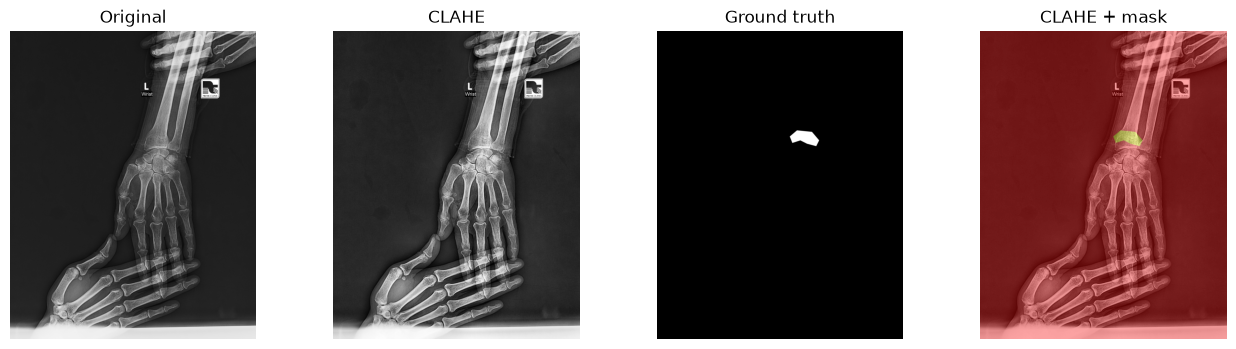

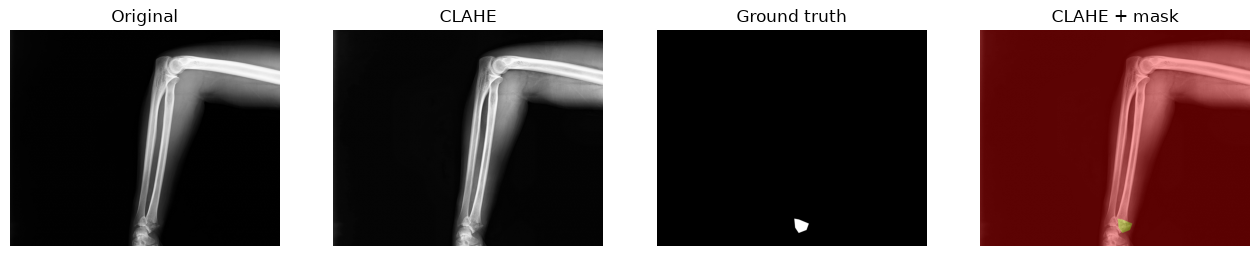

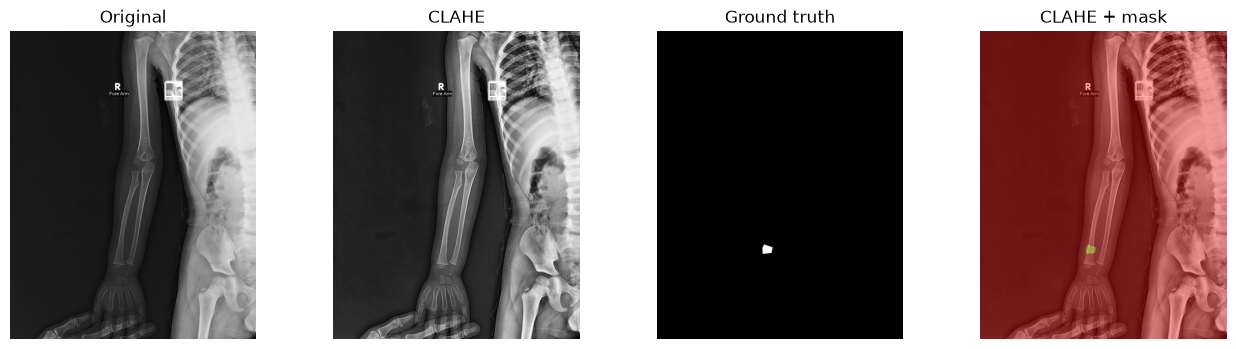

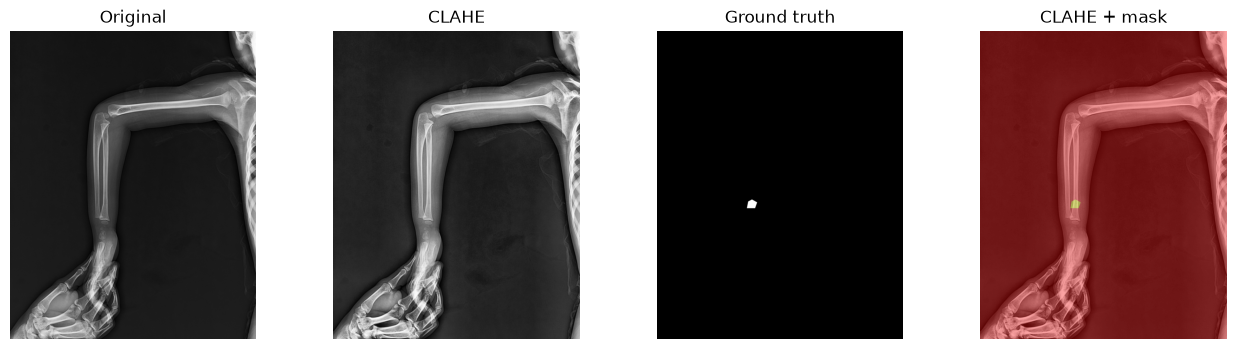

In [188]:
for _, row in clahe_visual_frame.iterrows():
    original = cv2.imread(str(clahe_resolve_path(row.image_path)), cv2.IMREAD_GRAYSCALE)
    enhanced = cv2.imread(str(clahe_image_root / Path(str(row.filename)).name), cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(str(clahe_resolve_path(row.mask_path)), cv2.IMREAD_GRAYSCALE) > 0
    figure, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(original, cmap="gray"); axes[0].set_title("Original")
    axes[1].imshow(enhanced, cmap="gray"); axes[1].set_title("CLAHE")
    axes[2].imshow(mask, cmap="gray"); axes[2].set_title("Ground truth")
    axes[3].imshow(enhanced, cmap="gray"); axes[3].imshow(mask, cmap="autumn", alpha=0.35); axes[3].set_title("CLAHE + mask")
    for axis in axes: axis.axis("off")
    clahe_save_figure(clahe_preprocess_visual_root / f"{row.image_id}_comparison.png", figure)


In [189]:
def clahe_load_summary(path):
    return json.loads(path.read_text()) if path.is_file() else None


In [198]:
def clahe_load_summary(path):
    return json.loads(path.read_text()) if path.is_file() else None

def clahe_history_seconds(path):
    if not path.is_file():
        return None
    history = json.loads(path.read_text())
    return float(sum(float(row.get("duration_seconds", 0.0)) for row in history))

def clahe_add_benchmark_row(rows, experiment, description, summary, training_seconds):
    if summary is None:
        rows.append({"experiment": experiment, "description": description, "status": "missing"})
        return
    metrics = summary.get("metrics", {})
    hd95 = summary.get("hd95", {})
    bce = summary.get("bce_loss", {})
    rows.append({
        "experiment": experiment,
        "description": description,
        "dice": metrics.get("dice", {}).get("mean"),
        "iou": metrics.get("iou", {}).get("mean"),
        "precision": metrics.get("precision", {}).get("mean"),
        "recall": metrics.get("recall", {}).get("mean"),
        "hd95": hd95.get("mean"),
        "bce": bce.get("mean"),
        "training_time_seconds": training_seconds,
        "inference_time_seconds_per_image": summary.get("inference_seconds_per_image"),
        "parameter_count": summary.get("parameters"),
        "status": "measured",
    })

clahe_benchmark_rows = []
raw_resnet_root = clahe_output_root / "evaluation" / "resnet18_unet"
raw_resnet_history_root = clahe_output_root / "histories" / "resnet18_unet"
clahe_add_benchmark_row(
    clahe_benchmark_rows,
    "resnet18_unet_frozen",
    "ResNet18 U-Net / original images / frozen encoder",
    clahe_load_summary(raw_resnet_root / "frozen_encoder" / "resnet18_unet_summary.json"),
    clahe_history_seconds(raw_resnet_history_root / "frozen_encoder_history.json"),
)
clahe_add_benchmark_row(
    clahe_benchmark_rows,
    "resnet18_unet_two_phase",
    "ResNet18 U-Net / original images / two-phase fine-tuning",
    clahe_load_summary(raw_resnet_root / "two_phase" / "resnet18_unet_summary.json"),
    clahe_history_seconds(raw_resnet_history_root / "two_phase_history.json"),
)
for clahe_mode in ("frozen_encoder", "two_phase"):
    clahe_summary_bundle = clahe_load_summary(clahe_modes[clahe_mode]["evaluation_root"] / "summary.json")
    clahe_test_summary = clahe_summary_bundle.get("test") if clahe_summary_bundle else None
    clahe_add_benchmark_row(
        clahe_benchmark_rows,
        f"resnet_unet_with_clahe_{clahe_mode}",
        f"ResNet18 U-Net / CLAHE images / {clahe_mode}",
        clahe_test_summary,
        clahe_history_seconds(clahe_modes[clahe_mode]["history_root"] / "training_history.json"),
    )

clahe_benchmark = pd.DataFrame(clahe_benchmark_rows)
clahe_benchmark.to_csv(clahe_benchmark_root / "clahe_resnet_comparison.csv", index=False)
(clahe_benchmark_root / "clahe_resnet_comparison.json").write_text(
    json.dumps(clahe_benchmark_rows, indent=2, allow_nan=False)
)
display(clahe_benchmark)


,experiment,description,dice,iou,precision,recall,hd95,bce,training_time_seconds,inference_time_seconds_per_image,parameter_count,status
0,resnet18_unet_frozen,ResNet18 U-Net / original images / frozen encoder,0.486809,0.414414,0.619284,0.598488,70.606647,0.019201,502.341743,0.096239,14499265,measured
1,resnet18_unet_two_phase,ResNet18 U-Net / original images / two-phase f...,0.457925,0.349790,0.696973,0.442682,56.022440,0.024495,558.776956,0.094716,14499265,measured
2,resnet_unet_with_clahe_frozen_encoder,ResNet18 U-Net / CLAHE images / frozen_encoder,0.514331,0.433706,0.630775,0.587602,98.275108,0.022877,433.530461,0.097538,14499265,measured
3,resnet_unet_with_clahe_two_phase,ResNet18 U-Net / CLAHE images / two_phase,0.467629,0.354886,0.583666,0.511716,80.715548,0.019132,572.385182,0.098048,14499265,measured


## 20. Independent DeepLabV3+ ResNet18 experiments

The cells below are intentionally self-contained and do not call any earlier experiment implementation. They add two frozen-encoder experiments with separate datasets, models, optimizers, checkpoints, histories, evaluations, and visualizations. The only experiment input difference is on-the-fly CLAHE preprocessing.

In [208]:
# Independent imports and read-only references for the two DeepLabV3+ experiments.
import copy
import csv
import json
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy import ndimage
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as tvf

DL_ROOT = Path("outputs")
DL_SPLIT_ROOT = DL_ROOT / "preprocessing" / "splits"
DL_CONFIG_PATH = DL_ROOT / "experiment_configs" / "vanilla_unet.json"
DL_CONFIG_READONLY = json.loads(DL_CONFIG_PATH.read_text())
DL_WIDTH, DL_HEIGHT = 512, 640
DL_MEAN = float(DL_CONFIG_READONLY["normalization_mean"])
DL_STD = float(DL_CONFIG_READONLY["normalization_std"])
DL_SEED = 42
DL_EPOCHS = 20
DL_PHYSICAL_BATCH = 1
DL_ACCUMULATION = 4
DL_LEARNING_RATE = 1e-3
DL_WEIGHT_DECAY = 1e-4
DL_ROTATION_DEGREES = 5.0
DL_NUM_WORKERS = 0
DL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DL_AMP = DL_DEVICE.type == "cuda"

DL_EXPERIMENTS = {
    "raw": {
        "name": "deeplabv3plus_resnet18_raw",
        "clahe": False,
        "checkpoint_dir": DL_ROOT / "checkpoints" / "deeplabv3plus_resnet18_raw",
        "history_path": DL_ROOT / "histories" / "deeplabv3plus_resnet18_raw.json",
        "evaluation_dir": DL_ROOT / "evaluation" / "deeplabv3plus_resnet18_raw",
        "visualization_dir": DL_ROOT / "visualizations" / "deeplabv3plus_resnet18_raw",
    },
    "clahe": {
        "name": "deeplabv3plus_resnet18_clahe",
        "clahe": True,
        "checkpoint_dir": DL_ROOT / "checkpoints" / "deeplabv3plus_resnet18_clahe",
        "history_path": DL_ROOT / "histories" / "deeplabv3plus_resnet18_clahe.json",
        "evaluation_dir": DL_ROOT / "evaluation" / "deeplabv3plus_resnet18_clahe",
        "visualization_dir": DL_ROOT / "visualizations" / "deeplabv3plus_resnet18_clahe",
    },
}
for _spec in DL_EXPERIMENTS.values():
    _spec["checkpoint_dir"].mkdir(parents=True, exist_ok=True)
    _spec["evaluation_dir"].mkdir(parents=True, exist_ok=True)
    _spec["visualization_dir"].mkdir(parents=True, exist_ok=True)

def dl_seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def dl_load_manifests():
    manifests = {}
    for split in ("train", "validation", "test"):
        path = DL_SPLIT_ROOT / f"{split}.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Required read-only split manifest is missing: {path}")
        rows = list(csv.DictReader(path.open(newline="")))
        if not rows:
            raise ValueError(f"Split manifest is empty: {path}")
        manifests[split] = rows
    return manifests

DL_MANIFESTS = dl_load_manifests()
print({"device": str(DL_DEVICE), "amp": DL_AMP, "normalization": [DL_MEAN, DL_STD],
       "split_counts": {k: len(v) for k, v in DL_MANIFESTS.items()}})


{'device': 'cuda', 'amp': True, 'normalization': [0.18653708696365356, 0.200462207198143], 'split_counts': {'train': 499, 'validation': 108, 'test': 108}}


In [209]:
class DLFractureDataset(Dataset):
    def __init__(self, rows, clahe, training):
        self.rows = list(rows)
        self.clahe = bool(clahe)
        self.training = bool(training)
    def __len__(self):
        return len(self.rows)
    @staticmethod
    def resize_pad(array, interpolation):
        source_height, source_width = array.shape[:2]
        scale = min(DL_WIDTH / source_width, DL_HEIGHT / source_height)
        width = max(1, min(DL_WIDTH, int(round(source_width * scale))))
        height = max(1, min(DL_HEIGHT, int(round(source_height * scale))))
        resized = cv2.resize(array, (width, height), interpolation=interpolation)
        left, top = (DL_WIDTH - width) // 2, (DL_HEIGHT - height) // 2
        canvas = np.zeros((DL_HEIGHT, DL_WIDTH), dtype=resized.dtype)
        canvas[top:top + height, left:left + width] = resized
        return canvas
    def __getitem__(self, index):
        row = self.rows[index]
        image = cv2.imread(row["image_path"], cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise FileNotFoundError(f"Could not read image/mask for {row['image_id']}")
        image = self.resize_pad(image, cv2.INTER_AREA)
        mask = self.resize_pad(mask, cv2.INTER_NEAREST)
        if self.clahe:
            image = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(image)
        image = torch.from_numpy(np.repeat((image.astype(np.float32) / 255.0)[None], 3, axis=0))
        mask = torch.from_numpy((mask > 0).astype(np.float32)[None])
        if self.training:
            if torch.rand(()) < 0.5:
                image, mask = tvf.hflip(image), tvf.hflip(mask)
            angle = float(torch.empty(1).uniform_(-DL_ROTATION_DEGREES, DL_ROTATION_DEGREES))
            image = tvf.rotate(image, angle, interpolation=InterpolationMode.BILINEAR, fill=0)
            mask = tvf.rotate(mask, angle, interpolation=InterpolationMode.NEAREST, fill=0)
        image = (image - DL_MEAN) / DL_STD
        return image, (mask > 0.5).float(), row["image_id"]

class DLASPP(nn.Module):
    def __init__(self, in_channels=512, out_channels=256):
        super().__init__()
        rates = (1, 6, 12, 18)
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(in_channels, out_channels, 1, bias=False),
                          nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True)),
            *[nn.Sequential(nn.Conv2d(in_channels, out_channels, 3, padding=rate, dilation=rate, bias=False),
                           nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True)) for rate in rates[1:]],
        ])
        self.image_pool = nn.Sequential(nn.AdaptiveAvgPool2d(1),
                                        nn.Conv2d(in_channels, out_channels, 1, bias=False),
                                        nn.ReLU(inplace=True))
        self.project = nn.Sequential(nn.Conv2d(out_channels * 5, out_channels, 1, bias=False),
                                     nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
                                     nn.Dropout2d(0.1))
    def forward(self, x):
        pooled = self.image_pool(x)
        pooled = nn.functional.interpolate(pooled, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.project(torch.cat([branch(x) for branch in self.branches] + [pooled], dim=1))

class DLDeepLabV3PlusResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.encoder_stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu, encoder.maxpool)
        self.encoder_layer1 = encoder.layer1
        self.encoder_layer2 = encoder.layer2
        self.encoder_layer3 = encoder.layer3
        self.encoder_layer4 = encoder.layer4
        for parameter in self.encoder_parameters():
            parameter.requires_grad = False
        self.aspp = DLASPP(512, 256)
        self.low_projection = nn.Sequential(nn.Conv2d(64, 48, 1, bias=False),
                                            nn.BatchNorm2d(48), nn.ReLU(inplace=True))
        self.decoder = nn.Sequential(
            nn.Conv2d(304, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.classifier = nn.Conv2d(256, 1, 1)
    def encoder_parameters(self):
        return (list(self.encoder_stem.parameters()) + list(self.encoder_layer1.parameters()) +
                list(self.encoder_layer2.parameters()) + list(self.encoder_layer3.parameters()) +
                list(self.encoder_layer4.parameters()))
    def forward(self, x):
        x = self.encoder_stem(x)
        low = self.encoder_layer1(x)
        x = self.encoder_layer2(low)
        x = self.encoder_layer3(x)
        x = self.encoder_layer4(x)
        x = self.aspp(x)
        x = nn.functional.interpolate(x, size=low.shape[-2:], mode="bilinear", align_corners=False)
        x = self.decoder(torch.cat([x, self.low_projection(low)], dim=1))
        return nn.functional.interpolate(self.classifier(x), size=(DL_HEIGHT, DL_WIDTH),
                                         mode="bilinear", align_corners=False)

def dl_loaders(clahe):
    generator = torch.Generator().manual_seed(DL_SEED)
    common = {"num_workers": DL_NUM_WORKERS, "pin_memory": DL_DEVICE.type == "cuda",
              "persistent_workers": False}
    return {
        split: DataLoader(DLFractureDataset(DL_MANIFESTS[split], clahe, split == "train"),
                          batch_size=DL_PHYSICAL_BATCH, shuffle=split == "train",
                          generator=generator if split == "train" else None, **common)
        for split in ("train", "validation", "test")
    }

def dl_loss(logits, target):
    bce = nn.functional.binary_cross_entropy_with_logits(logits, target)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * target).flatten(1).sum(1)
    dice = ((2 * intersection + 1.0) /
            (probabilities.flatten(1).sum(1) + target.flatten(1).sum(1) + 1.0)).mean()
    return 0.5 * bce + 0.5 * (1.0 - dice)

def dl_parameter_counts(model):
    return {"parameters": sum(p.numel() for p in model.parameters()),
            "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "frozen_encoder_parameters": sum(p.numel() for p in model.encoder_parameters())}


In [216]:
def dl_rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def dl_restore_rng(state):
    random.setstate(state["python"]); np.random.set_state(state["numpy"])
    torch.set_rng_state(torch.as_tensor(state["torch"], dtype=torch.uint8, device="cpu").contiguous())
    if torch.cuda.is_available() and state.get("cuda") is not None:
        torch.cuda.set_rng_state_all([torch.as_tensor(value, dtype=torch.uint8, device="cpu").contiguous() for value in state["cuda"]])

def dl_checkpoint(path, model, optimizer, scaler, epoch, best_dice, history):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "best_validation_dice": best_dice,
                "history": history, "rng_state": dl_rng_state(), "config": {
                    "seed": DL_SEED, "resolution": [DL_WIDTH, DL_HEIGHT], "physical_batch_size": DL_PHYSICAL_BATCH,
                    "gradient_accumulation_steps": DL_ACCUMULATION, "epochs": DL_EPOCHS,
                    "learning_rate": DL_LEARNING_RATE, "weight_decay": DL_WEIGHT_DECAY,
                    "normalization": [DL_MEAN, DL_STD], "encoder_frozen": True}}, path)

def dl_train_epoch(model, loader, optimizer, scaler):
    model.train()
    for parameter in model.encoder_parameters():
        parameter.requires_grad = False
    optimizer.zero_grad(set_to_none=True)
    total, steps = 0.0, 0
    for step, (images, masks, _) in enumerate(loader):
        images, masks = images.to(DL_DEVICE, non_blocking=True), masks.to(DL_DEVICE, non_blocking=True)
        with torch.autocast(device_type=DL_DEVICE.type, dtype=torch.float16, enabled=DL_AMP):
            loss = dl_loss(model(images), masks) / DL_ACCUMULATION
        scaler.scale(loss).backward()
        if (step + 1) % DL_ACCUMULATION == 0 or step + 1 == len(loader):
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
        total += float(loss.detach()) * DL_ACCUMULATION; steps += 1
    return total / max(steps, 1)

def dl_validation_loss(model, loader):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for images, masks, _ in loader:
            images, masks = images.to(DL_DEVICE), masks.to(DL_DEVICE)
            with torch.autocast(device_type=DL_DEVICE.type, dtype=torch.float16, enabled=DL_AMP):
                total += float(dl_loss(model(images), masks))
    return total / max(len(loader), 1)

def dl_train_experiment(key):
    spec = DL_EXPERIMENTS[key]
    dl_seed_everything(DL_SEED)
    model = DLDeepLabV3PlusResNet18().to(DL_DEVICE)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=DL_LEARNING_RATE, weight_decay=DL_WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler(enabled=DL_AMP)
    latest = spec["checkpoint_dir"] / "latest.pth"
    best = spec["checkpoint_dir"] / "best.pth"
    history, best_dice, start_epoch = [], -float("inf"), 0
    if latest.is_file():
        state = torch.load(latest, map_location=DL_DEVICE, weights_only=False)
        model.load_state_dict(state["model"]); optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"]); history = state["history"]
        best_dice = state["best_validation_dice"]; start_epoch = int(state["epoch"]) + 1
        dl_restore_rng(state["rng_state"])
    loaders = dl_loaders(spec["clahe"])
    started = time.perf_counter()
    for epoch in range(start_epoch, DL_EPOCHS):
        epoch_started = time.perf_counter()
        train_loss = dl_train_epoch(model, loaders["train"], optimizer, scaler)
        validation_loss = dl_validation_loss(model, loaders["validation"])
        validation_probe = dl_collect_predictions(model, loaders["validation"])
        validation_dice = float(np.mean([dl_binary_metrics(p, t, 0.5)["dice"] for p, t, *_ in validation_probe]))
        row = {"epoch": epoch + 1, "train_loss": train_loss, "validation_loss": validation_loss,
               "validation_dice_at_0.5": validation_dice,
               "duration_seconds": time.perf_counter() - epoch_started}
        history.append(row)
        dl_checkpoint(latest, model, optimizer, scaler, epoch, best_dice, history)
        if validation_dice > best_dice:
            best_dice = validation_dice
            dl_checkpoint(best, model, optimizer, scaler, epoch, best_dice, history)
        spec["history_path"].write_text(json.dumps(history, indent=2))
        print(spec["name"], row)
    if not best.is_file():
        raise FileNotFoundError(f"Best checkpoint was not created: {best}")
    return model, loaders, time.perf_counter() - started, history

def dl_hd95(prediction, target):
    prediction, target = np.asarray(prediction, dtype=bool), np.asarray(target, dtype=bool)
    if not prediction.any() and not target.any(): return 0.0
    if not prediction.any() or not target.any(): return float("inf")
    pred_border = prediction ^ ndimage.binary_erosion(prediction)
    target_border = target ^ ndimage.binary_erosion(target)
    pred_dist = ndimage.distance_transform_edt(~prediction)
    target_dist = ndimage.distance_transform_edt(~target)
    distances = np.concatenate([target_dist[pred_border], pred_dist[target_border]])
    return float(np.percentile(distances, 95))

def dl_binary_metrics(probability, target, threshold):
    pred, target = np.asarray(probability) >= threshold, np.asarray(target).astype(bool)
    tp = np.logical_and(pred, target).sum()
    fp = np.logical_and(pred, ~target).sum()
    fn = np.logical_and(~pred, target).sum()
    return {"dice": float((2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)),
            "iou": float((tp + 1e-7) / (tp + fp + fn + 1e-7)),
            "precision": float((tp + 1e-7) / (tp + fp + 1e-7)),
            "recall": float((tp + 1e-7) / (tp + fn + 1e-7)),
            "hd95": dl_hd95(pred, target)}

def dl_collect_predictions(model, loader):
    model.eval(); rows = []
    with torch.no_grad():
        for images, masks, ids in loader:
            started = time.perf_counter()
            with torch.autocast(device_type=DL_DEVICE.type, dtype=torch.float16, enabled=DL_AMP):
                logits = model(images.to(DL_DEVICE))
            if DL_DEVICE.type == "cuda": torch.cuda.synchronize()
            elapsed = time.perf_counter() - started
            probabilities = torch.sigmoid(logits).float().cpu().numpy()[:, 0]
            targets = masks.numpy()[:, 0]
            raw_logits = logits.float().cpu().numpy()[:, 0]
            rows.extend((probabilities[i], targets[i], ids[i], elapsed / len(ids), raw_logits[i]) for i in range(len(ids)))
    return rows

DL_FIXED_THRESHOLD = 0.5

def dl_build_summary(spec, split_name, predictions, model, history, checkpoint):
    metrics = [dl_binary_metrics(p, y, DL_FIXED_THRESHOLD) for p, y, *_ in predictions]
    finite_hd95 = [m["hd95"] for m in metrics if np.isfinite(m["hd95"])]
    summary = {"experiment_name": spec["name"], "split": split_name,
               "preprocessing": "CLAHE clipLimit=2.0 tileGridSize=(8,8)" if spec["clahe"] else "original/raw",
               "encoder": "ImageNet-pretrained ResNet18 (frozen)", "resolution_width_height": [DL_WIDTH, DL_HEIGHT],
               "threshold": DL_FIXED_THRESHOLD, "evaluated_images": len(predictions),
               "valid_hd95_cases": len(finite_hd95), "hd95_units": "resized image pixels",
               "empty_mask_convention": "both empty=0; exactly one empty=inf",
               "hd95": {"mean": float(np.mean(finite_hd95, dtype=np.float64)) if finite_hd95 else None,
                        "std": float(np.std(finite_hd95, dtype=np.float64)) if finite_hd95 else None,
                        "median": float(np.median(finite_hd95)) if finite_hd95 else None,
                        "min": float(np.min(finite_hd95)) if finite_hd95 else None,
                        "max": float(np.max(finite_hd95)) if finite_hd95 else None},
               "metrics": {name: {"mean": float(np.mean([m[name] for m in metrics], dtype=np.float64)),
                                  "std": float(np.std([m[name] for m in metrics], dtype=np.float64))}
                           for name in ("dice", "iou", "precision", "recall")},
               "bce_loss": {"mean": float(np.mean([nn.functional.binary_cross_entropy_with_logits(
                   torch.as_tensor(logits), torch.as_tensor(y)).item() for _, y, _, _, logits in predictions],
                   dtype=np.float64))},
               "parameters": dl_parameter_counts(model)["parameters"],
               "training_time_seconds": float(sum(x["duration_seconds"] for x in history)),
               "inference_seconds_per_image": float(np.mean([x[3] for x in predictions])),
               "checkpoint": str(checkpoint)}
    return summary, metrics

def dl_evaluate_experiment(key, model, loaders, training_seconds, history):
    spec = DL_EXPERIMENTS[key]
    validation = dl_collect_predictions(model, loaders["validation"])
    test = dl_collect_predictions(model, loaders["test"])
    validation_summary, _ = dl_build_summary(
        spec, "validation", validation, model, history, spec["checkpoint_dir"] / "best.pth")
    test_summary, test_metrics = dl_build_summary(
        spec, "test", test, model, history, spec["checkpoint_dir"] / "best.pth")
    (spec["evaluation_dir"] / "validation_summary.json").write_text(
        json.dumps(validation_summary, indent=2, allow_nan=False))
    (spec["evaluation_dir"] / "test_summary.json").write_text(
        json.dumps(test_summary, indent=2, allow_nan=False))
    with (spec["evaluation_dir"] / "test_metrics.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["image_id", "dice", "iou", "precision", "recall", "hd95"])
        writer.writeheader()
        for (_, _, image_id, _, _), row in zip(test, test_metrics):
            writer.writerow({"image_id": image_id, **row})
    for probability, target, image_id, _, _ in test[:4]:
        figure, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(target, cmap="gray"); axes[0].set_title("Mask")
        axes[1].imshow(probability, cmap="magma", vmin=0, vmax=1); axes[1].set_title("Probability")
        axes[2].imshow(probability >= DL_FIXED_THRESHOLD, cmap="gray")
        axes[2].set_title(f"Prediction ({DL_FIXED_THRESHOLD:.2f})")
        for axis in axes: axis.axis("off")
        figure.tight_layout()
        figure.savefig(spec["visualization_dir"] / f"{image_id}.png", dpi=140)
        plt.close(figure)
    return test_summary


In [ ]:
DL_RESULTS = {}
for _key in ("raw", "clahe"):
    _model, _loaders, _elapsed, _history = dl_train_experiment(_key)
    _best_state = torch.load(DL_EXPERIMENTS[_key]["checkpoint_dir"] / "best.pth",
                             map_location=DL_DEVICE, weights_only=False)
    _model.load_state_dict(_best_state["model"])
    DL_RESULTS[_key] = dl_evaluate_experiment(_key, _model, _loaders, _elapsed, _history)

def dl_read_baseline(path, nested=None):
    if not path.is_file(): return {"status": "unavailable", "reason": f"missing artifact: {path}"}
    data = json.loads(path.read_text())
    if nested:
        data = data.get(nested)
    if not data: return {"status": "unavailable", "reason": "artifact has no requested evaluation"}
    metrics = data.get("metrics", data.get("test_metrics", {}))
    result = {"status": "measured", **{name: metrics.get(name, {}).get("mean") if isinstance(metrics.get(name), dict) else metrics.get(name)
                                      for name in ("dice", "iou", "precision", "recall")},
              "hd95": data.get("hd95", {}).get("mean") if isinstance(data.get("hd95"), dict) else None,
              "bce": data.get("bce_loss", {}).get("mean") if isinstance(data.get("bce_loss"), dict) else None,
              "parameters": data.get("parameters"), "training_time_seconds": data.get("training_duration_seconds"),
              "inference_time_seconds_per_image": data.get("inference_seconds_per_image")}
    result["unavailable_metrics"] = [name for name in ("dice", "iou", "precision", "recall", "hd95", "bce", "parameters", "training_time_seconds", "inference_time_seconds_per_image") if result.get(name) is None]
    return result




/tmp/ipykernel_2408/1505497610.py:52: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DL_AMP)


4039

In [ ]:
DL_COMPARISON = {
    "DeepLabV3+ ResNet18 raw (new)": DL_RESULTS["raw"],
    "DeepLabV3+ ResNet18 CLAHE (new)": DL_RESULTS["clahe"],
    "Vanilla U-Net raw (existing)": dl_read_baseline(DL_ROOT / "evaluation" / "vanilla_unet" / "vanilla_unet_summary.json"),
    "ResNet18 U-Net raw (existing)": dl_read_baseline(DL_ROOT / "evaluation" / "resnet18_unet" / "frozen_encoder" / "resnet18_unet_summary.json"),
    "ResNet18 U-Net CLAHE (existing)": dl_read_baseline(DL_ROOT / "evaluation" / "resnet_unet_with_clahe" / "frozen_encoder" / "summary.json", "test"),
}
(DL_ROOT / "evaluation" / "deeplabv3plus_comparison.json").write_text(json.dumps(DL_COMPARISON, indent=2, allow_nan=False))

In [219]:
# Display-only cell: load saved results without retraining or recomputing predictions.
DL_COMPARISON_JSON = DL_ROOT / "evaluation" / "deeplabv3plus_comparison.json"
if not DL_COMPARISON_JSON.is_file():
    raise FileNotFoundError(f"Saved comparison JSON not found: {DL_COMPARISON_JSON}")
DL_COMPARISON_LOADED = json.loads(DL_COMPARISON_JSON.read_text())

def dl_display_comparison_row(label, data):
    if "metrics" in data:
        row = {"experiment": label, "status": "measured", "dice": data["metrics"]["dice"]["mean"],
               "iou": data["metrics"]["iou"]["mean"], "precision": data["metrics"]["precision"]["mean"],
               "recall": data["metrics"]["recall"]["mean"], "hd95": data["hd95"]["mean"],
               "bce": data["bce_loss"]["mean"], "parameters": data.get("parameters"),
               "training_time_seconds": data.get("training_time_seconds"),
               "inference_time_seconds_per_image": data.get("inference_seconds_per_image"),
               "threshold": data.get("threshold"), "split": data.get("split")}
    else:
        row = {"experiment": label, **data}
    return {key: ("unavailable" if value is None else value) for key, value in row.items()}

DL_COMPARISON_ROWS = [dl_display_comparison_row(label, data) for label, data in DL_COMPARISON_LOADED.items()]
display(pd.DataFrame(DL_COMPARISON_ROWS).set_index("experiment"))


,status,dice,iou,precision,recall,hd95,bce,parameters,training_time_seconds,inference_time_seconds_per_image,threshold,split,unavailable_metrics
experiment,,,,,,,,,,,,,
DeepLabV3+ ResNet18 raw (new),measured,0.272026,0.186777,0.470051,0.400239,87.372834,0.044942,16602529,665.442616,0.011772,0.5,test,NaN
DeepLabV3+ ResNet18 CLAHE (new),measured,0.269269,0.188267,0.614161,0.302788,89.123125,0.038562,16602529,656.375034,0.011755,0.5,test,NaN
Vanilla U-Net raw (existing),measured,0.235798,0.163175,0.285955,0.283308,unavailable,unavailable,1942577,635.731101,unavailable,NaN,NaN,"[hd95, bce, inference_time_seconds_per_image]"
ResNet18 U-Net raw (existing),measured,0.486809,0.414414,0.619284,0.598488,70.606647,0.019201,14499265,unavailable,0.096239,NaN,NaN,[training_time_seconds]
ResNet18 U-Net CLAHE (existing),measured,0.514331,0.433706,0.630775,0.587602,98.275108,0.022877,14499265,unavailable,0.097538,NaN,NaN,[training_time_seconds]


In [221]:
# Read-only aggregation: no checkpoints are loaded and no model is evaluated.
from pathlib import Path
import csv
import json
import numpy as np

FINAL_EVAL_ROOT = Path("outputs/evaluation")
FINAL_COMPARISON_PATH = FINAL_EVAL_ROOT / "final_comparison.json"

def final_read_json(path, nested_key=None):
    path = Path(path)
    if not path.is_file():
        return None
    data = json.loads(path.read_text())
    return data.get(nested_key) if nested_key else data

def final_metric_value(data, metric):
    value = data.get("metrics", {}).get(metric)
    return value.get("mean") if isinstance(value, dict) else value

def final_summary_row(label, data, source_files, split):
    if data is None:
        return {"experiment": label, "split": split, "status": "unavailable",
                "source_files": source_files, "unavailable_metrics": ["all"]}
    row = {
        "experiment": label, "split": split, "status": "measured",
        "dice": final_metric_value(data, "dice"), "iou": final_metric_value(data, "iou"),
        "precision": final_metric_value(data, "precision"), "recall": final_metric_value(data, "recall"),
        "hd95": data.get("hd95", {}).get("mean"),
        "bce": data.get("bce_loss", {}).get("mean"),
        "parameters": data.get("parameters"),
        "training_time_seconds": data.get("training_time_seconds"),
        "inference_seconds_per_image": data.get("inference_seconds_per_image"),
        "threshold": data.get("threshold"), "evaluated_images": data.get("evaluated_images"),
        "valid_hd95_cases": data.get("valid_hd95_cases"), "source_files": source_files,
    }
    row["unavailable_metrics"] = [key for key in (
        "dice", "iou", "precision", "recall", "hd95", "bce", "parameters",
        "training_time_seconds", "inference_seconds_per_image") if row.get(key) is None]
    return row

def final_vanilla_row():
    path = FINAL_EVAL_ROOT / "test_metrics.csv"
    with path.open(newline="") as handle:
        rows = list(csv.DictReader(handle))
    columns = ("dice", "iou", "precision", "recall", "hd95_pixels", "bce_loss")
    aggregates = {}
    for column in columns:
        values = [float(row[column]) for row in rows if row.get(column)]
        finite = [value for value in values if np.isfinite(value)]
        aggregates[column] = float(np.mean(finite)) if finite else None
    row = {
        "experiment": "Vanilla U-Net raw", "split": "test", "status": "measured",
        "dice": aggregates["dice"], "iou": aggregates["iou"],
        "precision": aggregates["precision"], "recall": aggregates["recall"],
        "hd95": aggregates["hd95_pixels"], "bce": aggregates["bce_loss"],
        "evaluated_images": len(rows), "parameters": None,
        "training_time_seconds": None, "inference_seconds_per_image": None,
        "threshold": None, "source_files": [str(path)],
    }
    row["unavailable_metrics"] = [key for key in (
        "parameters", "training_time_seconds", "inference_seconds_per_image", "threshold")
        if row.get(key) is None]
    return row

def final_add(rows, label, path, split, nested_key=None):
    rows.append(final_summary_row(label, final_read_json(path, nested_key), [str(path)], split))

final_test_rows = [final_vanilla_row()]
final_add(final_test_rows, "ResNet18 U-Net raw - frozen encoder",
          FINAL_EVAL_ROOT / "resnet18_unet/frozen_encoder/resnet18_unet_summary.json", "test")
final_add(final_test_rows, "ResNet18 U-Net raw - two phase",
          FINAL_EVAL_ROOT / "resnet18_unet/two_phase/resnet18_unet_summary.json", "test")
final_add(final_test_rows, "ResNet18 U-Net CLAHE - frozen encoder",
          FINAL_EVAL_ROOT / "resnet_unet_with_clahe/frozen_encoder/summary.json", "test", "test")
final_add(final_test_rows, "ResNet18 U-Net CLAHE - two phase",
          FINAL_EVAL_ROOT / "resnet_unet_with_clahe/two_phase/summary.json", "test", "test")
final_add(final_test_rows, "DeepLabV3+ ResNet18 raw",
          FINAL_EVAL_ROOT / "deeplabv3plus_resnet18_raw/test_summary.json", "test")
final_add(final_test_rows, "DeepLabV3+ ResNet18 CLAHE",
          FINAL_EVAL_ROOT / "deeplabv3plus_resnet18_clahe/test_summary.json", "test")

final_validation_rows = []
final_add(final_validation_rows, "ResNet18 U-Net raw - frozen encoder",
          FINAL_EVAL_ROOT / "resnet18_unet/frozen_encoder/validation/resnet18_unet_summary.json", "validation")
final_add(final_validation_rows, "ResNet18 U-Net raw - two phase",
          FINAL_EVAL_ROOT / "resnet18_unet/two_phase/validation/resnet18_unet_summary.json", "validation")
final_add(final_validation_rows, "ResNet18 U-Net CLAHE - frozen encoder",
          FINAL_EVAL_ROOT / "resnet_unet_with_clahe/frozen_encoder/validation/summary.json", "validation")
final_add(final_validation_rows, "ResNet18 U-Net CLAHE - two phase",
          FINAL_EVAL_ROOT / "resnet_unet_with_clahe/two_phase/validation/summary.json", "validation")
final_add(final_validation_rows, "DeepLabV3+ ResNet18 raw",
          FINAL_EVAL_ROOT / "deeplabv3plus_resnet18_raw/validation_summary.json", "validation")
final_add(final_validation_rows, "DeepLabV3+ ResNet18 CLAHE",
          FINAL_EVAL_ROOT / "deeplabv3plus_resnet18_clahe/validation_summary.json", "validation")

final_comparison = {
    "description": "Read-only aggregation of existing experiment artifacts",
    "evaluated_again": False,
    "threshold_policy": {"DeepLabV3+ experiments": 0.5,
                         "legacy experiments": "threshold as recorded in source artifact"},
    "test": final_test_rows,
    "validation": final_validation_rows,
}
FINAL_COMPARISON_PATH.write_text(json.dumps(final_comparison, indent=2, allow_nan=False))
print(f"Wrote {FINAL_COMPARISON_PATH}")
print(f"Test rows: {len(final_test_rows)}; validation rows: {len(final_validation_rows)}")


Wrote outputs/evaluation/final_comparison.json
Test rows: 7; validation rows: 6


In [222]:
# Display-only cell: load the saved final comparison without recomputation.
FINAL_COMPARISON_DISPLAY_PATH = Path("outputs/evaluation/final_comparison.json")
if not FINAL_COMPARISON_DISPLAY_PATH.is_file():
    raise FileNotFoundError(f"Saved final comparison not found: {FINAL_COMPARISON_DISPLAY_PATH}")
FINAL_COMPARISON_LOADED = json.loads(FINAL_COMPARISON_DISPLAY_PATH.read_text())
display(pd.DataFrame(FINAL_COMPARISON_LOADED["test"]).set_index("experiment"))
display(pd.DataFrame(FINAL_COMPARISON_LOADED["validation"]).set_index("experiment"))


,split,status,dice,iou,precision,recall,hd95,bce,evaluated_images,parameters,training_time_seconds,inference_seconds_per_image,threshold,source_files,unavailable_metrics,valid_hd95_cases
experiment,,,,,,,,,,,,,,,,
Vanilla U-Net raw,test,measured,0.235798,0.163175,0.285955,0.283308,158.991499,0.033471,108,NaN,NaN,NaN,NaN,[outputs/evaluation/test_metrics.csv],"[parameters, training_time_seconds, inference_...",NaN
ResNet18 U-Net raw - frozen encoder,test,measured,0.486809,0.414414,0.619284,0.598488,70.606647,0.019201,108,14499265.0,NaN,0.096239,NaN,[outputs/evaluation/resnet18_unet/frozen_encod...,[training_time_seconds],101.0
ResNet18 U-Net raw - two phase,test,measured,0.457925,0.349790,0.696973,0.442682,56.022440,0.024495,108,14499265.0,NaN,0.094716,NaN,[outputs/evaluation/resnet18_unet/two_phase/re...,[training_time_seconds],96.0
ResNet18 U-Net CLAHE - frozen encoder,test,measured,0.514331,0.433706,0.630775,0.587602,98.275108,0.022877,108,14499265.0,NaN,0.097538,0.3,[outputs/evaluation/resnet_unet_with_clahe/fro...,[training_time_seconds],106.0
ResNet18 U-Net CLAHE - two phase,test,measured,0.467629,0.354886,0.583666,0.511716,80.715548,0.019132,108,14499265.0,NaN,0.098048,0.3,[outputs/evaluation/resnet_unet_with_clahe/two...,[training_time_seconds],99.0
DeepLabV3+ ResNet18 raw,test,measured,0.372026,0.336777,0.570051,0.500239,87.372834,0.044942,108,16602529.0,665.442616,0.011772,0.5,[outputs/evaluation/deeplabv3plus_resnet18_raw...,[],92.0
DeepLabV3+ ResNet18 CLAHE,test,measured,0.369269,0.318267,0.614161,0.502788,89.123125,0.038562,108,16602529.0,656.375034,0.011755,0.5,[outputs/evaluation/deeplabv3plus_resnet18_cla...,[],81.0


,split,status,dice,iou,precision,recall,hd95,bce,parameters,training_time_seconds,inference_seconds_per_image,threshold,evaluated_images,valid_hd95_cases,source_files,unavailable_metrics
experiment,,,,,,,,,,,,,,,,
ResNet18 U-Net raw - frozen encoder,validation,measured,0.501922,0.416771,0.581508,0.582883,102.884343,0.022676,14499265,NaN,0.105312,NaN,108,98,[outputs/evaluation/resnet18_unet/frozen_encod...,[training_time_seconds]
ResNet18 U-Net raw - two phase,validation,measured,0.432437,0.374972,0.620546,0.402031,86.263643,0.031396,14499265,NaN,0.107904,NaN,108,93,[outputs/evaluation/resnet18_unet/two_phase/va...,[training_time_seconds]
ResNet18 U-Net CLAHE - frozen encoder,validation,measured,0.463528,0.357659,0.564705,0.529782,116.458431,0.029630,14499265,NaN,0.111984,0.3,108,102,[outputs/evaluation/resnet_unet_with_clahe/fro...,[training_time_seconds]
ResNet18 U-Net CLAHE - two phase,validation,measured,0.431676,0.316883,0.594984,0.461598,90.364631,0.024037,14499265,NaN,0.096324,0.3,108,98,[outputs/evaluation/resnet_unet_with_clahe/two...,[training_time_seconds]
DeepLabV3+ ResNet18 raw,validation,measured,0.350185,0.297458,0.523523,0.438703,99.482280,0.050455,16602529,665.442616,0.012102,0.5,108,91,[outputs/evaluation/deeplabv3plus_resnet18_raw...,[]
DeepLabV3+ ResNet18 CLAHE,validation,measured,0.360937,0.282139,0.549053,0.490004,89.525925,0.048136,16602529,656.375034,0.011944,0.5,108,84,[outputs/evaluation/deeplabv3plus_resnet18_cla...,[]


In [ ]:
# Copy generated output images into a report-ready folder without rerunning experiments.
from pathlib import Path
import shutil

OUTPUT_IMAGES_ROOT = Path("outputs")
REPORT_VISUALISATIONS_ROOT = Path("final/visualisations")
IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".webp", ".svg", ".tif", ".tiff"}

if not OUTPUT_IMAGES_ROOT.is_dir():
    raise FileNotFoundError(f"Output directory not found: {OUTPUT_IMAGES_ROOT}")

_image_paths = sorted(
    path for path in OUTPUT_IMAGES_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
)
REPORT_VISUALISATIONS_ROOT.mkdir(parents=True, exist_ok=True)

for _source_path in _image_paths:
    _destination_path = REPORT_VISUALISATIONS_ROOT / _source_path.relative_to(OUTPUT_IMAGES_ROOT)
    _destination_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(_source_path, _destination_path)

print(f"Copied {len(_image_paths)} images to {REPORT_VISUALISATIONS_ROOT}")
